# UI-PRMD 위치 + XYZ에서 계산한 각도 기반 TCN — Colab 학습

목표: M01 Deep Squat, M03 Inline Lunge, M04 Side Lunge, M09 Standing Shoulder Internal-External Rotation과 IDLE Standing Rest의 **5클래스** 분류. 입력은 정규화된 공통 XYZ 36개와 각도 특징 18개, 총 54개입니다. 자세의 정확성/재활 품질 점수가 아닙니다.

Colab에서 **런타임 → 런타임 유형 변경 → GPU**를 선택하고 위에서부터 실행하세요. Movements.zip과 webcam_recordings.json을 Google Drive에 올리고 아래 경로를 수정합니다. 모델은 실행 후 생성되며 이 노트북에는 사전 학습 결과가 없습니다.

### 데이터 선택과 중요한 좌표 차이
이 폴더의 Vicon Positions는 39개 광학 마커의 XYZ 궤적(117열)입니다. Kinect Positions는 루트를 제외하면 부모 좌표계의 상대 위치라서 단순 합산만으로 MediaPipe와 대응시킬 수 없습니다. **UI-PRMD Angles를 읽지 않고 XYZ에서 각도를 계산하는 baseline**을 위해 Vicon을 사용합니다. Vicon의 마커 위치는 해부학적 관절 중심과 정확히 같지 않습니다. 특히 골반 중심은 아래 마커 평균으로 근사합니다.

|공통 관절 순서|Vicon 마커 (1-based)|MediaPipe (0-based)|
|---|---|---|
|왼/오른 어깨|10 / 17|11 / 12|
|왼/오른 팔꿈치|12 / 19|13 / 14|
|왼/오른 손목|평균(14,15) / 평균(21,22)|15 / 16|
|왼/오른 골반|평균(24,26) / 평균(25,27)|23 / 24|
|왼/오른 무릎|29 / 35|25 / 26|
|왼/오른 발목|31 / 37|27 / 28|

출처: [UI-PRMD 원 논문, Table 2 및 데이터 수집 설명](https://www.mdpi.com/2306-5729/3/1/2), [데이터 제공 페이지](https://www.idahofallshighered.org/vakanski/ui-prmd.html), [MediaPipe Pose Landmarker](https://developers.google.com/edge/mediapipe/solutions/vision/pose_landmarker).
Vicon m03_s03은 원 데이터에서 누락되어 선택 클래스는 총 39개 녹화입니다. Vicon의 100 Hz를 30 Hz로 낮춰 MediaPipe 스트림을 가정합니다. MediaPipe에서는 이미지 정규화 좌표가 아닌 **pose_world_landmarks의 XYZ**를 보내세요. 센서 차이 때문에 여기서 얻는 정확도는 실제 MediaPipe 정확도가 아닙니다.


**재학습 필수:** 기존 모델에서 idle이 추가된 5클래스 [B,90,54] 위치+각도 모델로 바꿉니다. 기존 가중치는 재사용하지 않습니다.
새 결과는 `ui_prmd_tcn_output.zip`으로 저장합니다. 기존 위치 모델의 정확도를 새 모델 결과로 해석하지 마세요.

M09 전환: 기존 12관절/54특징을 유지합니다. 팔꿈치·손목의 몸 기준 XYZ가 전완의 방향 변화를 포함하지만, 기존 관절 내각만으로 어깨 축회전을 직접 측정하는 것은 아닙니다. M09는 팔꿈치를 약 90도로 굽힌 채 전완을 앞뒤로 회전하는 동작입니다. 손목만 비트는 동작과 구분하세요. 실제 MediaPipe M09 녹화로 별도 평가해야 합니다. 기존 M06 웹캠 녹화를 M09로 이름만 바꾸면 안 됩니다.


## 웹캠 idle 수집 → 5클래스 학습 안내
브라우저에서 카메라를 켜고 idle을 **30초 × 5회** 기록합니다. train 3회, val 1회, test 1회로 지정하고 `webcam_recordings.json`을 다운로드해 Drive에 올립니다. 한 사람의 첫 실험을 위한 시작 분량이며 정확도를 보장하지 않습니다. 각 녹화는 5초 준비 시간 뒤 시작하고, 매 녹화 사이에 팔 모양·거리·위치를 조금 바꾸세요.

idle은 사람이 서서 운동하지 않는 대기 상태입니다. 운동 자세 유지나 사람 없음은 idle 녹화로 넣지 마세요. 영상을 저장하지 않고 기존 순서의 12개 world XYZ/visibility/timestamp만 기록합니다.

**분할 주의:** Vicon은 기존 사람 단위 분할을 유지합니다. 한 사람의 웹캠 녹화는 녹화 단위로 분리하므로 전체 평가는 새로운 사람에 대한 5클래스 일반화 성능이 아닙니다. 중복 녹화 ID/동일 콘텐츠는 거부하지만 사람이 ID를 바꾸거나 구간을 복사하면 자동 검사가 모두 잡을 수는 없습니다. 여럿을 수집하면 사람별 split을 지정하고 STRICT_WEBCAM_SUBJECT_SPLIT=True를 사용하세요.

**센서 차이:** idle만 MediaPipe, 운동만 Vicon이면 센서 특성이 라벨과 겹칩니다. 같은 녹화 UI에서 실제 웹캠 4개 운동도 수집해 추가할 수 있습니다. 본인의 webcam 운동 test가 없으면 운동→idle 오분류율은 실제 웹캠 성능을 나타내지 않습니다.

녹화 파일의 수동 라벨을 사용하며 기존 모델 예측은 라벨에 사용하지 않습니다. XYZ를 먼저 30 Hz로 보간한 뒤 학습/서버 공통 함수로 [90,54] 특징을 생성합니다. 원본의 연속한 3초 창에 visibility<0.5 또는 gap>200ms가 있으면 해당 창을 제외합니다. 모든 split에 실제 idle 창이 있어야 학습을 진행합니다. 사람 없는 구간을 0 좌표로 채우지 않습니다.

기존 5클래스 가중치와 결과는 수정하지 않으며 이 노트북은 **5클래스 모델을 처음부터 재학습**합니다. 결과 경로는 ui_prmd_tcn_output으로 유지되므로 기존 결과는 별도 보관하세요.


In [1]:
import sys, json, random, re, hashlib, shutil, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.signal import resample_poly
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, confusion_matrix)
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
print('Python', sys.version, 'Torch', torch.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


Python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] Torch 2.14.1+cu130
Device: cuda


## 1. 데이터 준비
Google Drive 모드가 기본입니다. 이미 /content/Movements에 압축을 풀었다면 MODE='existing'을 사용합니다. 로컬 Jupyter에서도 DATA_ROOT를 자신의 Movements 경로로 지정할 수 있습니다. 기존 데이터 폴더를 자동 덮어쓰지 않습니다.


In [2]:
MODE = 'drive'  # 'drive', 'upload', 'existing'
ZIP_PATH = '/content/drive/MyDrive/Colab Notebooks/machineLearing/pose-tcn/Movements.zip'
WEBCAM_JSON = Path('/content/drive/MyDrive/Colab Notebooks/machineLearing/pose-tcn/webcam_recordings.json')
STRICT_WEBCAM_SUBJECT_SPLIT = False  # True requires different people in each split
DATA_ROOT = Path('/content/Movements')
OUT = Path('/content/ui_prmd_tcn_output')
OUT.mkdir(parents=True, exist_ok=True)
if MODE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
elif MODE == 'upload':
    from google.colab import files
    uploaded = files.upload()
    zips = [p for p in uploaded if p.lower().endswith('.zip')]
    if len(zips) != 1: raise ValueError('Movements.zip 하나를 업로드하세요.')
    ZIP_PATH = zips[0]
    del uploaded
elif MODE != 'existing':
    raise ValueError('지원하지 않는 MODE')
if MODE != 'existing' and not DATA_ROOT.exists():
    dest = DATA_ROOT.parent.resolve()
    with zipfile.ZipFile(ZIP_PATH) as z:
        for member in z.infolist():
            target = (dest / member.filename).resolve()
            if not target.is_relative_to(dest): raise ValueError('안전하지 않은 ZIP 경로')
        z.extractall(dest)
POSITION_DIR = DATA_ROOT / 'Vicon' / 'Positions'
assert POSITION_DIR.is_dir(), f'폴더를 확인하세요: {POSITION_DIR}'
print('Data:', POSITION_DIR)

# upload 모드에서는 웹캠 JSON을 별도로 업로드합니다.
if MODE == 'upload':
    uploaded_json = files.upload()
    json_names = [name for name in uploaded_json if name.endswith('.json')]
    if len(json_names) != 1: raise ValueError('webcam_recordings.json 하나를 업로드하세요.')
    WEBCAM_JSON = Path(json_names[0])
    del uploaded_json
assert WEBCAM_JSON.exists(), f'웹캠 녹화 JSON이 필요합니다: {WEBCAM_JSON}'


Mounted at /content/drive
Data: /content/Movements/Vicon/Positions


## 2. 공통 XYZ → 위치 36 + 각도 18 (학습/서버 동일 코드)

원 데이터는 Vicon Positions의 39마커이며 위 표의 12개 공통 관절로 변환합니다. Kinect/Vicon **Angles 파일은 사용하지 않습니다**.
선택 마커의 0 벡터/비유한값은 결측으로 처리하고, 결측률 5% 이하·연속 0.3초 이하만 선형 보간합니다. 이후 XYZ를 100→30 Hz로 anti-alias resampling하고 90프레임 창을 만듭니다.
서버는 수신 XYZ를 timestamp 기준 30 Hz로 선형 보간합니다. **두 경로 모두 XYZ 보간 이후 같은 `window_features()`로 각도를 계산**합니다. 센서별 시간 샘플링 차이는 있지만 위치 정규화·각도 공식·특징 순서·단위는 같습니다.

### 위치 블록: 최종 입력 0~35
프레임별 골반 중점을 빼고, 창 전체의 어깨 중점–골반 중점 거리 중앙값으로 나눕니다. 창 평균의 좌→우 골반 벡터를 수평면에 투영해 lateral축을 만들고, up축 및 depth=cross(lateral,up)으로 XYZ를 변환합니다. 축은 창 전체에서 고정하며 몸통 기울기는 보존합니다.
12관절 순서 × [lateral, up, depth]로 평탄화합니다. 위치는 부호가 있고 0~1로 제한되지 않습니다. 단위는 몸통 길이 대비 상대 거리이며, 절대 위치와 신체 크기는 제거합니다.

### 각도 블록: 최종 입력 36~53
아래 표의 0~17은 각도 블록 내부 인덱스입니다. 최종 입력에서는 36을 더합니다.

### 공식과 각도 순서
3점 A, B, C의 B 관절 내각은 u=A−B, v=C−B로 두고

`θ = arccos(clip(dot(u/||u||, v/||v||), -1, 1)) / π`

를 사용합니다. 0~1은 0~180°입니다. 무릎을 곧게 펴면 1이며, 임상적 굴곡각 0°와는 정의가 다릅니다. 길이 0인 뼈 벡터는 가짜 각도 0으로 바꾸지 않고 오류로 거부합니다. 각도 계산에서는 중심/스케일을 수치 안정성에만 사용합니다. 별도의 위치 특징은 정규화 후 입력에 포함합니다.

|인덱스|특징|정의|
|---|---|---|
|0,1|좌/우 무릎|골반–무릎–발목의 내각|
|2,3|좌/우 골반|어깨–골반–무릎의 내각|
|4,5|좌/우 팔꿈치|어깨–팔꿈치–손목의 내각|
|6,7|좌/우 어깨|팔꿈치–어깨–골반의 내각|
|8|허벅지 사이|좌/우 골반→무릎 벡터 사이 각도|
|9|종아리 사이|좌/우 무릎→발목 벡터 사이 각도|
|10|몸통 기울기|골반 중점→어깨 중점과 수직 위쪽 사이|
|11,12|좌/우 허벅지 기울기|골반→무릎과 수직 아래쪽 사이|
|13,14|좌/우 종아리 기울기|무릎→발목과 수직 아래쪽 사이|
|15|무릎 비대칭|abs(특징0 − 특징1)|
|16|골반 비대칭|abs(특징2 − 특징3)|
|17|허벅지 기울기 비대칭|abs(특징11 − 특징12)|

Vicon의 up=[0,0,1], MediaPipe world의 up=[0,-1,0]을 사용합니다. 회전 불변인 관절 내각과 달리 수직축 특징은 카메라가 수평이라는 가정이 필요합니다. 카메라 기울기는 별도 보정 대상입니다.
스쿼트/인라인 런지 구분을 위해 양쪽 다리의 굽힘과 방향 차이를 명시적으로 제공합니다. 이것이 정확도 향상을 보장하지는 않으며 MediaPipe 도메인 차이는 남아 있습니다.

### 누수 방지 및 학습 파라미터
피험자 train s01–s06 / validation s07–s08 / test s09–s10 분리 후 창을 생성합니다. stride=30, 90프레임(3초) 창은 녹화 경계를 넘지 않습니다. 한 창은 반복 1회 라벨이 아닙니다.
평균/표준편차는 train 특징에서만 계산하고 저장 모델 내부에 넣습니다. Train에만 50% 확률로 두 블록의 좌우 특징을 함께 교환합니다. 위치의 lateral 성분만 부호를 반전하고 각도·절대 비대칭 특징은 부호를 바꾸지 않습니다.

TCN: channels=64, kernel=3, dilation=1/2/4/8, block당 causal Conv1d 2개, dropout=0.2, receptive field=61프레임, 시간 평균 pooling. AdamW lr=0.001, weight_decay=0.0001, batch=64, 최대 100 epochs, validation macro-F1 15회 무개선 시 중단. Train 클래스 빈도 기반 weighted CE를 사용합니다.

**공유 소스:** 아래 셀은 프로젝트 `pose_features.py`의 원문을 포함합니다. 수정할 때 `python scripts/sync_notebook_features.py`로 동기화하세요. Colab에는 이 ipynb만 업로드해도 실행됩니다. 저장된 소스 SHA-256·특징 이름·입력 차원을 서버에서 검사하여 다른 공식이나 기존 위치 모델과 섞이지 않게 합니다.

위치와 각도의 단위가 다르므로 54채널 각각을 train 평균/표준편차로 표준화합니다. 각도는 XYZ에서 결정되는 값이므로 새 센서 정보가 추가되는 것은 아닙니다. 공간 배치와 굽힘을 함께 표현하는 실험입니다.


In [3]:
CLASSES = ['M01 Deep Squat', 'M03 Inline Lunge', 'M04 Side Lunge',
           'M09 Standing Shoulder Internal-External Rotation', 'IDLE Standing Rest']
CODES = ['m01','m03','m04','m09','idle']
NUM_CLASSES = len(CODES)
MOVEMENT_CODES = CODES[:-1]
JOINTS = ['left_shoulder','right_shoulder','left_elbow','right_elbow',
          'left_wrist','right_wrist','left_hip','right_hip',
          'left_knee','right_knee','left_ankle','right_ankle']
VICON_GROUPS = [[9],[16],[11],[18],[13,14],[20,21],[23,25],[24,26],[28],[34],[30],[36]]
MP_IDS = [11,12,13,14,15,16,23,24,25,26,27,28]
CFG = dict(source_fps=100, target_fps=30, window=90, stride=30,
           channels=64, dilations=[1,2,4,8], kernel=3, dropout=0.2,
           batch_size=64, epochs=100, patience=15, lr=1e-3, weight_decay=1e-4,
           seed=SEED, num_classes=NUM_CLASSES)
SPLITS = {'train':list(range(1,7)), 'val':[7,8], 'test':[9,10]}
assert not (set(SPLITS['train']) & set(SPLITS['val']) or
            set(SPLITS['train']) & set(SPLITS['test']) or
            set(SPLITS['val']) & set(SPLITS['test']))


In [6]:
PREPROCESS_SOURCE = '"""Shared Colab/server contract: body-normalized XYZ (36) + angles (18).\n\nOnly the selected 12 XYZ joints are used. No UI-PRMD Angles files are read.\nEdit this file, then run scripts/sync_notebook_features.py before training.\n"""\nimport numpy as np\n\nFEATURE_SCHEMA = \'positions_angles_v1\'\nJOINTS = [\'left_shoulder\', \'right_shoulder\', \'left_elbow\', \'right_elbow\',\n          \'left_wrist\', \'right_wrist\', \'left_hip\', \'right_hip\',\n          \'left_knee\', \'right_knee\', \'left_ankle\', \'right_ankle\']\nMP_IDS = [11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]\nANGLE_NAMES = [\n    \'left_knee\', \'right_knee\', \'left_hip\', \'right_hip\',\n    \'left_elbow\', \'right_elbow\', \'left_shoulder\', \'right_shoulder\',\n    \'thigh_spread\', \'shin_spread\', \'trunk_to_up\',\n    \'left_thigh_to_down\', \'right_thigh_to_down\',\n    \'left_shin_to_down\', \'right_shin_to_down\',\n    \'knee_asymmetry\', \'hip_asymmetry\', \'thigh_tilt_asymmetry\',\n]\nANGLE_MIRROR_INDICES = [1, 0, 3, 2, 5, 4, 7, 6, 8, 9, 10, 12, 11, 14, 13, 15, 16, 17]\nPOSITION_NAMES = [f\'{joint}_{axis}\' for joint in JOINTS for axis in (\'lateral\',\'up\',\'depth\')]\nFEATURE_NAMES = POSITION_NAMES + ANGLE_NAMES\nFEATURE_UNITS = [\'torso_length\'] * 36 + [\'radians/pi\'] * 18\nMIRROR_INDICES = [joint * 3 + axis for joint in (1,0,3,2,5,4,7,6,9,8,11,10)\n                  for axis in range(3)] + [36 + i for i in ANGLE_MIRROR_INDICES]\nMIRROR_SIGNS = [-1 if i % 3 == 0 else 1 for i in range(36)] + [1] * 18\n\n\ndef angle_between(u, v):\n    """arccos(clip(dot(unit(u), unit(v)), -1, 1)) / pi; output in [0,1]."""\n    u, v = np.asarray(u, dtype=np.float64), np.asarray(v, dtype=np.float64)\n    nu, nv = np.linalg.norm(u, axis=-1, keepdims=True), np.linalg.norm(v, axis=-1, keepdims=True)\n    if np.any(nu < 1e-8) or np.any(nv < 1e-8):\n        raise ValueError(\'Degenerate joint vector; cannot compute angle\')\n    cosine = np.sum((u / nu) * (v / nv), axis=-1)\n    return np.arccos(np.clip(cosine, -1., 1.)) / np.pi\n\n\ndef angle_features(points, up):\n    """[T,12,3] resampled XYZ -> [T,18] float32, before train standardization.\n\n    Vicon: up=[0,0,1]. MediaPipe world: up=[0,-1,0].\n    Triple (A,B,C) measures the interior angle at B: A-B versus C-B.\n    Thus an extended knee is 180 degrees (1.0), not zero flexion.\n    """\n    p = np.asarray(points, dtype=np.float64)\n    vertical = np.asarray(up, dtype=np.float64)\n    if p.ndim != 3 or p.shape[1:] != (12, 3) or len(p) == 0 or not np.isfinite(p).all():\n        raise ValueError(\'Expected finite [time,12,3] points\')\n    if vertical.shape != (3,) or not np.isfinite(vertical).all() or np.linalg.norm(vertical) < 1e-8:\n        raise ValueError(\'Invalid up axis\')\n    vertical = vertical / np.linalg.norm(vertical)\n    center = (p[:, 6] + p[:, 7]) / 2\n    torso = (p[:, 0] + p[:, 1]) / 2 - center\n    scale = np.linalg.norm(torso, axis=-1)\n    if np.any(scale < 1e-8):\n        raise ValueError(\'Degenerate torso\')\n    # Translation/scale do not change angles. Normalize for a unit-independent\n    # degeneracy tolerance across Vicon millimeters and MediaPipe meters.\n    p = (p - center[:, None, :]) / scale[:, None, None]\n\n    def joint(a, b, c):\n        return angle_between(p[:, a]-p[:, b], p[:, c]-p[:, b])\n\n    values = [joint(6,8,10), joint(7,9,11), joint(0,6,8), joint(1,7,9),\n              joint(0,2,4), joint(1,3,5), joint(2,0,6), joint(3,1,7)]\n    lt, rt = p[:,8]-p[:,6], p[:,9]-p[:,7]\n    ls, rs = p[:,10]-p[:,8], p[:,11]-p[:,9]\n    trunk = (p[:,0]+p[:,1])/2 - (p[:,6]+p[:,7])/2\n    values += [angle_between(lt,rt), angle_between(ls,rs), angle_between(trunk,vertical),\n               angle_between(lt,-vertical), angle_between(rt,-vertical),\n               angle_between(ls,-vertical), angle_between(rs,-vertical)]\n    values += [np.abs(values[0]-values[1]), np.abs(values[2]-values[3]),\n               np.abs(values[11]-values[12])]\n    return np.stack(values, axis=-1).astype(np.float32)\n\n\ndef position_features(points, up):\n    """Hip-centered XYZ in a window-fixed body basis, scaled by median torso length.\n\n    Lateral = horizontal left-to-right hip direction; depth = lateral cross up.\n    Keep gravity-based vertical instead of aligning with the tilted torso.\n    """\n    p = np.asarray(points, dtype=np.float64)\n    vertical = np.asarray(up, dtype=np.float64)\n    if p.ndim != 3 or p.shape[1:] != (12,3) or not len(p) or not np.isfinite(p).all():\n        raise ValueError(\'Expected finite [time,12,3] points\')\n    if vertical.shape != (3,) or not np.isfinite(vertical).all() or np.linalg.norm(vertical) < 1e-8:\n        raise ValueError(\'Invalid up axis\')\n    vertical = vertical / np.linalg.norm(vertical)\n    center = (p[:,6] + p[:,7]) / 2\n    scale = np.median(np.linalg.norm((p[:,0]+p[:,1])/2-center, axis=-1))\n    if scale < 1e-8:\n        raise ValueError(\'Degenerate torso\')\n    centered = (p-center[:,None,:])/scale\n    # Mean, rather than component-wise median, preserves rotation equivariance.\n    lateral = np.mean(centered[:,7]-centered[:,6], axis=0)\n    lateral -= np.dot(lateral,vertical)*vertical\n    if np.linalg.norm(lateral) < 1e-8:\n        raise ValueError(\'Degenerate horizontal hip direction\')\n    lateral /= np.linalg.norm(lateral)\n    basis = np.stack([lateral,vertical,np.cross(lateral,vertical)], axis=1)\n    return (centered @ basis).reshape(len(p),36).astype(np.float32)\n\n\ndef window_features(points, up):\n    """[T,12,3] -> [T,54]: 36 positions followed by 18 angles.\n\n    Both feature groups use the same resampled XYZ. Train standardization is\n    per feature channel and happens inside the exported model, not here.\n    """\n    return np.concatenate([position_features(points,up), angle_features(points,up)],axis=-1)\n\n\ndef resample_window(points, timestamps_ms, window=90, fps=30):\n    """Resample XYZ first, then compute angles; never interpolate angle values.\n\n    Matches the current permissive streaming policy: long gaps are interpolated.\n    Visibility is not used as an angle feature or a filter.\n    """\n    p = np.asarray(points, dtype=np.float64)\n    times = np.asarray(timestamps_ms, dtype=np.float64) / 1000\n    if p.shape != (len(times),12,3) or not np.isfinite(p).all():\n        raise ValueError(\'Expected finite timestamped [time,12,3] points\')\n    if len(times) < 2 or not np.isfinite(times).all() or np.any(np.diff(times) <= 0):\n        raise ValueError(\'Timestamps must be finite and strictly increasing\')\n    if window < 2 or fps <= 0:\n        raise ValueError(\'Invalid window/fps\')\n    target = times[-1] - np.arange(window-1,-1,-1)/fps\n    if target[0] < times[0]-1e-6:\n        raise ValueError(\'Insufficient window history\')\n    flat = p.reshape(len(p),36)\n    return np.stack([np.interp(target,times,flat[:,k]) for k in range(36)],axis=-1).reshape(window,12,3)\n\n\ndef mediapipe_json_window(payload, window=90, fps=30):\n    """Exported notebook/server adapter for a buffered list of 33-landmark frames."""\n    if payload.get(\'coordinate_system\') != \'mediapipe_world\':\n        raise ValueError(\'Only MediaPipe world landmarks are supported\')\n    frames = payload[\'frames\']\n    if any(len(frame[\'landmarks\']) != 33 for frame in frames):\n        raise ValueError(\'Need 33 landmarks per frame\')\n    points = [[[frame[\'landmarks\'][j][axis] for axis in (\'x\',\'y\',\'z\')]\n               for j in MP_IDS] for frame in frames]\n    sampled = resample_window(points, [frame[\'timestamp_ms\'] for frame in frames], window, fps)\n    return window_features(sampled, [0,-1,0])\n'
exec(PREPROCESS_SOURCE)
CFG['input_features'] = len(FEATURE_NAMES)
(OUT/'preprocess.py').write_text(PREPROCESS_SOURCE, encoding='utf-8')


7381

In [4]:
RECORDING_SOURCE = '"""Read browser JSON and build leak-audited 3-second windows for Colab/local use.\n\nFeature calculation is injected from the shared training/server preprocessing.\nNo model prediction is used as a training label.\n"""\nimport hashlib\nimport json\nfrom pathlib import Path\nimport numpy as np\n\nRECORDING_CODES = [\'m01\',\'m03\',\'m04\',\'m09\',\'idle\']\n\n\ndef load_webcam_windows(path, joint_names, mp_ids, feature_fn, resample_fn,\n                        window=90, fps=30, stride=30):\n    path=Path(path)\n    paths=sorted(path.rglob(\'*.json\')) if path.is_dir() else [path]\n    if not paths or not all(p.is_file() for p in paths):\n        raise ValueError(f\'No webcam recording JSON found: {path}\')\n    result={s:[] for s in (\'train\',\'val\',\'test\')}\n    audit=[]; sessions=set(); hashes=set()\n    duration=(window-1)*1000/fps\n    for file in paths:\n        data=json.loads(file.read_text(encoding=\'utf-8\'))\n        if (data.get(\'format\')!=\'pose_tcn_recordings_v1\'\n            or data.get(\'coordinate_system\')!=\'mediapipe_world\'\n            or data.get(\'joints\')!=list(joint_names) or data.get(\'mediapipe_indices\')!=list(mp_ids)):\n            raise ValueError(f\'{file.name}: recording format/joint order mismatch\')\n        for r in data[\'recordings\']:\n            sid=r[\'session_id\']; subject=r[\'subject_id\']; split=r[\'split\']; label=r[\'label\']\n            if not isinstance(sid,str) or not sid or sid in sessions:\n                raise ValueError(\'Duplicate or invalid recording session ID; do not copy sessions across splits\')\n            if not isinstance(subject,str) or not subject or split not in result or label not in RECORDING_CODES:\n                raise ValueError(f\'{sid}: invalid subject/split/label\')\n            sessions.add(sid)\n            if r.get(\'completion\')!=\'completed\':\n                raise ValueError(f\'{sid}: interrupted recording. Remove it in the browser and record again.\')\n            times=np.asarray([f[\'timestamp_ms\'] for f in r[\'frames\']],dtype=np.float64)\n            if len(times)<2 or not np.isfinite(times).all() or np.any(np.diff(times)<=0):\n                raise ValueError(f\'{sid}: insufficient or non-monotonic timestamps\')\n            if any(len(f[\'joints\'])!=12 for f in r[\'frames\']):\n                raise ValueError(f\'{sid}: expected 12 joints\')\n            points=np.asarray([[[p[k] for k in (\'x\',\'y\',\'z\')] for p in f[\'joints\']]\n                               for f in r[\'frames\']],dtype=np.float64)\n            visibility=np.asarray([[p[\'visibility\'] for p in f[\'joints\']] for f in r[\'frames\']],dtype=np.float64)\n            if (not np.isfinite(points).all() or not np.isfinite(visibility).all()\n                or np.any(visibility<0) or np.any(visibility>1)):\n                raise ValueError(f\'{sid}: invalid coordinates/visibility\')\n            digest=hashlib.sha256(points.tobytes()+(times-times[0]).tobytes()).hexdigest()\n            if digest in hashes:\n                raise ValueError(f\'{sid}: duplicate recording contents, even with a different ID\')\n            hashes.add(digest)\n            accepted=0; rejected=0\n            # Choose observed endpoints at ~stride/fps intervals. Use the same\n            # ending-at-latest-frame interpolation as the server.\n            endpoints=np.arange(times[0]+duration,times[-1]+1e-6,stride*1000/fps)\n            for endpoint in endpoints:\n                end=int(np.searchsorted(times,endpoint))\n                if end>=len(times): continue\n                begin=int(np.searchsorted(times,times[end]-duration,side=\'right\'))-1\n                if begin<0: continue\n                ts=times[begin:end+1]; xyz=points[begin:end+1]\n                if np.max(np.diff(ts))>200 or np.min(visibility[begin:end+1])<.5:\n                    rejected+=1; continue\n                try:\n                    sampled=resample_fn(xyz,ts,window,fps)\n                    features=feature_fn(sampled,[0,-1,0])\n                except ValueError:\n                    rejected+=1; continue\n                result[split].append(dict(features=features,label=RECORDING_CODES.index(label),\n                    file=f\'webcam_{sid}\',subject=f\'mp_{subject}\',session_id=sid,\n                    start_frame=-1,start_ms=float(ts[-1]-duration),source=\'mediapipe\'))\n                accepted+=1\n            audit.append(dict(file=file.name,session_id=sid,subject=f\'mp_{subject}\',split=split,\n                label=label,frames=len(times),seconds=float((times[-1]-times[0])/1000),\n                accepted_windows=accepted,rejected_windows=rejected,sha256=digest))\n            if not accepted:\n                raise ValueError(f\'{sid}: no usable 3-second window (visibility, gaps or pose geometry). Record again.\')\n    for split, rows in result.items():\n        if not any(r[\'label\']==RECORDING_CODES.index(\'idle\') for r in rows):\n            raise ValueError(f\'{split}: at least one independent idle recording with valid windows is required\')\n    return result,audit\n'
exec(RECORDING_SOURCE)
assert CODES == RECORDING_CODES, 'Notebook and webcam class orders must match'


motion,m01,m03,m04,m09
split,,,,
test,2,2,2,2
train,6,5,6,6
val,2,2,2,2


,subject,split,label,seconds,accepted_windows,rejected_windows
0,mp_person01,train,idle,29.9654,27,0
1,mp_person01,train,idle,29.9819,28,0
2,mp_person01,train,idle,29.9655,27,0
3,mp_person01,val,idle,29.9486,27,0
4,mp_person01,test,idle,29.9653,27,0


주의: 웹캠은 동일인 녹화 간 평가이며 새로운 사람에 대한 검증이 아닙니다: ['mp_person01']
주의: 운동=Vicon, idle=MediaPipe이므로 센서 차이를 학습할 수 있습니다. 웹캠 운동 평가를 추가하세요.
train (637, 90, 54) [149 112 158 136  82]
val (241, 90, 54) [59 61 56 38 27]
test (231, 90, 54) [52 51 50 51 27]


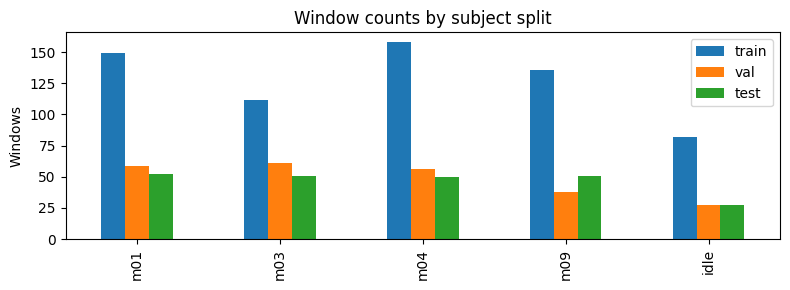

In [7]:
def read_vicon(path):
    first = path.open().readline()
    raw = np.loadtxt(path, delimiter=',' if ',' in first else None, ndmin=2)
    if raw.shape[1] != 117: raise ValueError(f'{path.name}: expected 117 columns, got {raw.shape}')
    p = raw.reshape(-1,39,3)
    chosen = sorted(set(sum(VICON_GROUPS, [])))
    missing = ~np.isfinite(p).all(-1) | np.all(p==0,axis=-1)
    for j in chosen:
        mask = missing[:,j]
        runs = re.findall('1+', ''.join(mask.astype(int).astype(str)))
        if mask.mean()>0.05 or max(map(len,runs),default=0)>30:
            raise ValueError(f'{path.name}: excessive missing marker {j+1}')
        for axis in range(3):
            p[:,j,axis] = np.interp(np.arange(len(p)), np.flatnonzero(~mask), p[~mask,j,axis])
    common = np.stack([p[:,g].mean(1) for g in VICON_GROUPS],axis=1)
    return resample_poly(common,3,10,axis=0).astype(np.float32), len(raw), float(missing[:,chosen].mean())

records, manifest = [], []
for path in sorted(POSITION_DIR.glob('*.txt')):
    match = re.fullmatch(r'(m\d{2})_s(\d{2})_positions.txt', path.name)
    if not match or match[1] not in MOVEMENT_CODES: continue
    motion, subject = match[1], int(match[2])
    split = next((k for k,v in SPLITS.items() if subject in v), None)
    if split is None: raise ValueError(f'Unknown subject: {subject}')
    p, n_raw, missing_rate = read_vicon(path)
    if len(p)<CFG['window']: raise ValueError(f'Short recording: {path}')
    records.append(dict(points=p, label=CODES.index(motion), subject=subject,
                        split=split, file=path.name))
    manifest.append(dict(file=path.name, subject=subject, motion=motion, split=split,
                         raw_frames=n_raw, frames_30hz=len(p), missing_rate=missing_rate,
                         sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
manifest = pd.DataFrame(manifest)
expected = {(m,s) for m in MOVEMENT_CODES for s in range(1,11)} - {('m03',3)}
actual = {(r['motion'],r['subject']) for r in manifest.to_dict('records')}
assert actual == expected, f'Dataset mismatch. Missing: {expected-actual}; extra: {actual-expected}'
display(manifest.groupby(['split','motion']).size().unstack(fill_value=0))
manifest.to_csv(OUT/'data_manifest.csv',index=False)

webcam, webcam_audit = load_webcam_windows(
    WEBCAM_JSON, JOINTS, MP_IDS, window_features, resample_window,
    CFG['window'], CFG['target_fps'], CFG['stride'])
webcam_manifest = pd.DataFrame(webcam_audit)
webcam_manifest.to_csv(OUT/'webcam_manifest.csv',index=False)
display(webcam_manifest[['subject','split','label','seconds','accepted_windows','rejected_windows']])
subject_splits = webcam_manifest.groupby('subject')['split'].nunique()
shared_subjects = subject_splits[subject_splits>1].index.tolist()
if shared_subjects:
    print('주의: 웹캠은 동일인 녹화 간 평가이며 새로운 사람에 대한 검증이 아닙니다:',shared_subjects)
    if STRICT_WEBCAM_SUBJECT_SPLIT:
        raise ValueError('Strict subject split: the same webcam person occurs in multiple splits')
if set(webcam_manifest.label)=={'idle'}:
    print('주의: 운동=Vicon, idle=MediaPipe이므로 센서 차이를 학습할 수 있습니다. 웹캠 운동 평가를 추가하세요.')
X, Y, META = {}, {}, {}
for split in SPLITS:
    xs, ys, ms = [], [], []
    for r in records:
        if r['split'] != split: continue
        for start in range(0,len(r['points'])-CFG['window']+1,CFG['stride']):
            xs.append(window_features(r['points'][start:start+CFG['window']], [0,0,1]))
            ys.append(r['label'])
            ms.append(dict(file=r['file'],subject=f"ui_s{r['subject']:02d}",start_frame=start,source='vicon'))
    for r in webcam[split]:
        xs.append(r['features']); ys.append(r['label'])
        ms.append({k:v for k,v in r.items() if k not in ('features','label')})
    X[split], Y[split], META[split] = np.stack(xs), np.array(ys), pd.DataFrame(ms)
    assert set(Y[split]) == set(range(NUM_CLASSES))
    print(split, X[split].shape, np.bincount(Y[split],minlength=NUM_CLASSES))
mean = X['train'].mean(axis=(0,1),keepdims=True)
std = np.maximum(X['train'].std(axis=(0,1),keepdims=True), 1e-3)
np.savez(OUT/'normalization.npz', mean=mean, std=std)
fig, ax = plt.subplots(figsize=(8,3))
pd.DataFrame({s:np.bincount(Y[s],minlength=NUM_CLASSES) for s in SPLITS},index=CODES).plot.bar(ax=ax)
ax.set(title='Window counts by subject split',ylabel='Windows'); plt.tight_layout(); plt.show()


### 학습 전 통합 입력 중 각도 시계열 확인
각 클래스의 첫 train 창에서 좌우 무릎·골반 각도와 비대칭을 확인합니다. 그림에만 180을 곱하여 도 단위로 표시하고, 각도 블록은 radians/π, 위치 블록은 몸통 길이 기준 좌표로 유지합니다. 샘플 하나의 모양은 클래스 전체를 대표하지 않습니다.


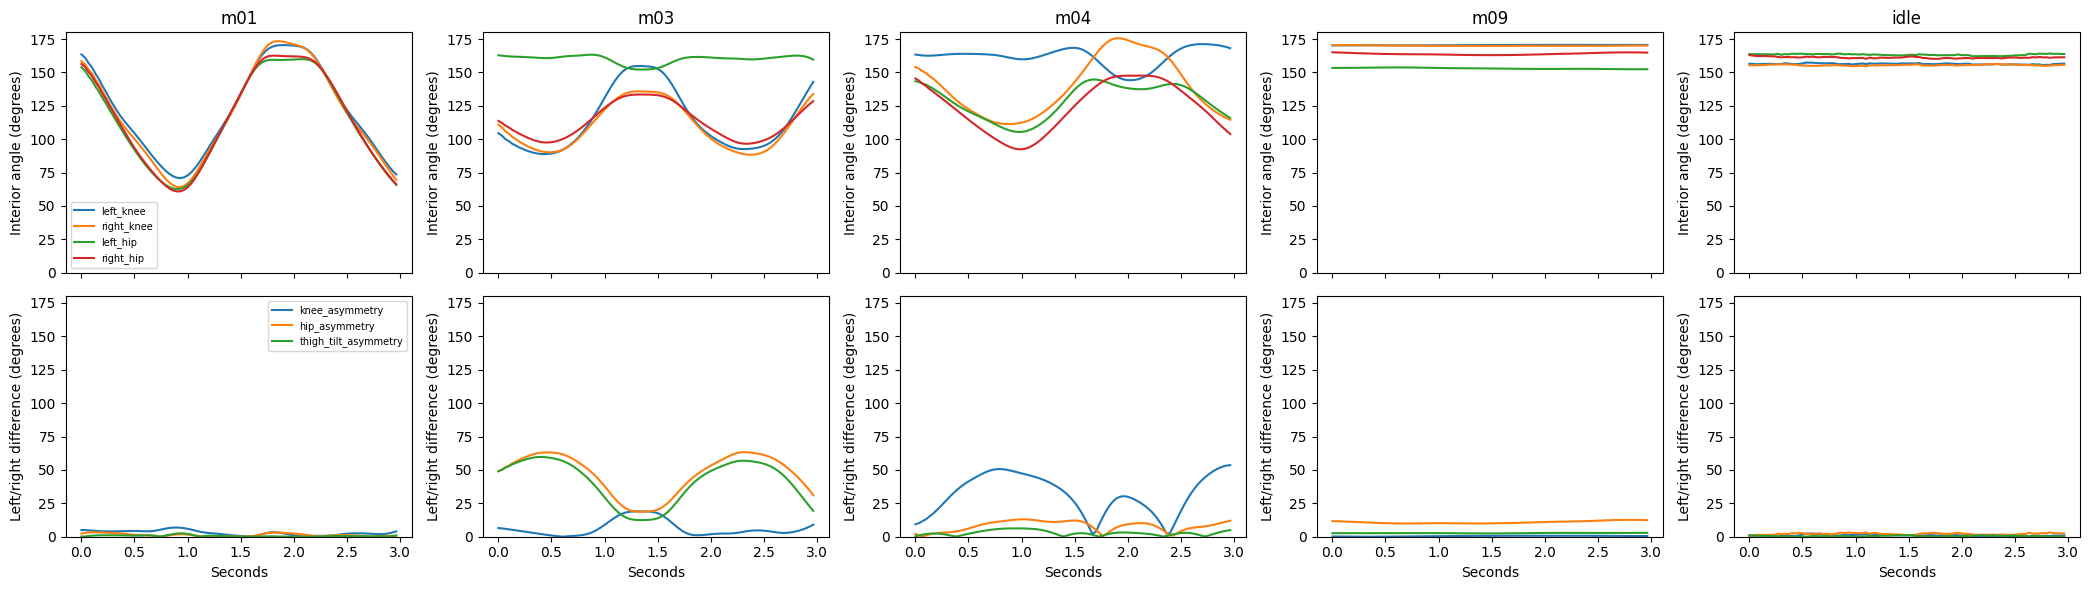

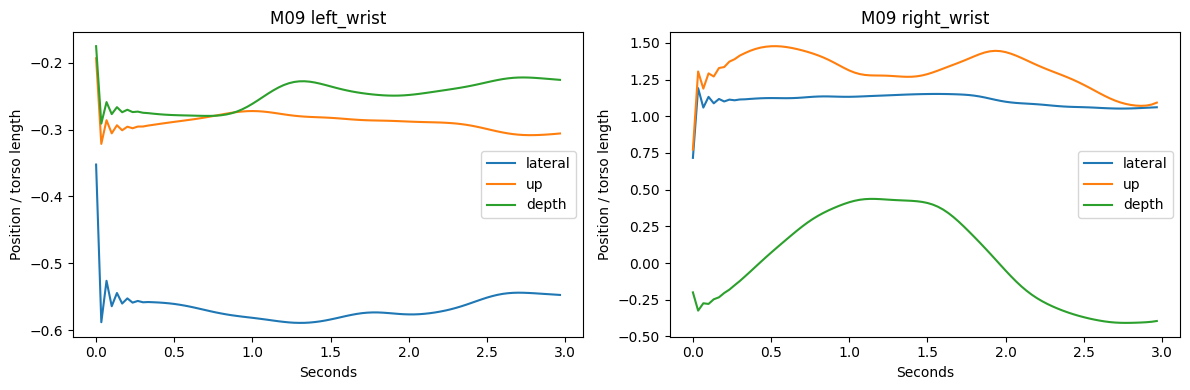

In [8]:
fig, axes = plt.subplots(2,NUM_CLASSES,figsize=(21,6),sharex=True)
for label in range(NUM_CLASSES):
    sample=X['train'][np.flatnonzero(Y['train']==label)[0],:,36:]
    t=np.arange(CFG['window'])/CFG['target_fps']
    for k in [0,1,2,3]:
        axes[0,label].plot(t,sample[:,k]*180,label=ANGLE_NAMES[k])
    for k in [15,16,17]:
        axes[1,label].plot(t,sample[:,k]*180,label=ANGLE_NAMES[k])
    axes[0,label].set(title=CODES[label],ylabel='Interior angle (degrees)',ylim=(0,180))
    axes[1,label].set(xlabel='Seconds',ylabel='Left/right difference (degrees)',ylim=(0,180))
axes[0,0].legend(fontsize=7); axes[1,0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT/'angle_preview.png',dpi=160); plt.show()

# Inspect upper-limb positions as well: elbow angles alone do not encode axial rotation.
m09_sample = X['train'][np.flatnonzero(Y['train']==CODES.index('m09'))[0]]
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,joint in zip(axes,['left_wrist','right_wrist']):
    start=JOINTS.index(joint)*3
    for axis,name in enumerate(['lateral','up','depth']):
        ax.plot(t,m09_sample[:,start+axis],label=name)
    ax.set(title='M09 '+joint,xlabel='Seconds',ylabel='Position / torso length')
    ax.legend()
plt.tight_layout(); plt.savefig(OUT/'m09_wrist_preview.png',dpi=160); plt.show()


## 3. 위치+각도 TCN 학습
입력 [batch,90,54] → 모델 내부 train 평균/표준편차 표준화 → [batch,54,90] → causal dilated residual Conv1d → 시간 평균 pooling → 5 logits.
첫 Conv1d 입력 채널을 `CFG['input_features']`로 설정합니다. 기존 위치 모델 가중치를 로드하지 않고 처음부터 학습합니다. Validation으로만 최적 epoch를 선택하며, test는 최종 평가에 사용합니다.


Parameters: 101765
epoch 001 | train loss 0.6362 | val F1 1.0000 | best 1.0000
epoch 002 | train loss 0.0115 | val F1 1.0000 | best 1.0000
epoch 003 | train loss 0.0014 | val F1 1.0000 | best 1.0000
epoch 004 | train loss 0.0007 | val F1 1.0000 | best 1.0000
epoch 005 | train loss 0.0004 | val F1 1.0000 | best 1.0000
epoch 006 | train loss 0.0004 | val F1 1.0000 | best 1.0000
epoch 007 | train loss 0.0003 | val F1 1.0000 | best 1.0000
epoch 008 | train loss 0.0003 | val F1 1.0000 | best 1.0000
epoch 009 | train loss 0.0002 | val F1 1.0000 | best 1.0000
epoch 010 | train loss 0.0002 | val F1 1.0000 | best 1.0000
epoch 011 | train loss 0.0002 | val F1 1.0000 | best 1.0000
epoch 012 | train loss 0.0002 | val F1 1.0000 | best 1.0000
epoch 013 | train loss 0.0002 | val F1 1.0000 | best 1.0000
epoch 014 | train loss 0.0001 | val F1 1.0000 | best 1.0000
epoch 015 | train loss 0.0001 | val F1 1.0000 | best 1.0000
epoch 016 | train loss 0.0001 | val F1 1.0000 | best 1.0000


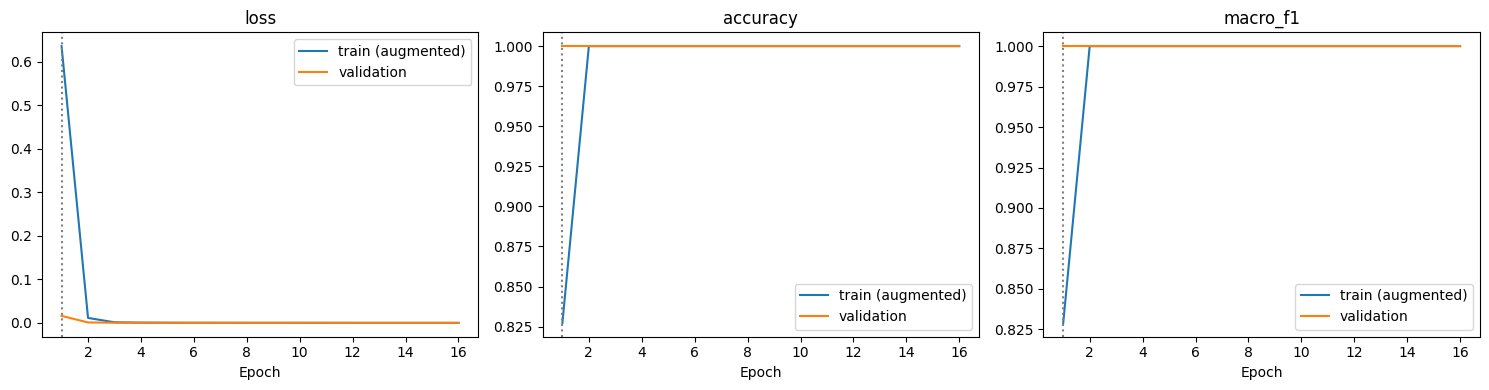

In [9]:
MODEL_SOURCE = "import torch\nfrom torch import nn\nimport torch.nn.functional as F\n\nclass TemporalBlock(nn.Module):\n    def __init__(self, cin, cout, dilation, kernel, dropout):\n        super().__init__()\n        self.pad = (kernel-1)*dilation\n        self.c1 = nn.Conv1d(cin,cout,kernel,dilation=dilation)\n        self.c2 = nn.Conv1d(cout,cout,kernel,dilation=dilation)\n        self.n1 = nn.LayerNorm(cout)\n        self.n2 = nn.LayerNorm(cout)\n        self.drop = nn.Dropout(dropout)\n        self.skip = nn.Conv1d(cin,cout,1) if cin!=cout else nn.Identity()\n    def forward(self,x):\n        z = self.c1(F.pad(x,(self.pad,0)))\n        z = self.drop(F.relu(self.n1(z.transpose(1,2)).transpose(1,2)))\n        z = self.c2(F.pad(z,(self.pad,0)))\n        z = self.drop(F.relu(self.n2(z.transpose(1,2)).transpose(1,2)))\n        return F.relu(z+self.skip(x))\n\nclass PoseTCN(nn.Module):\n    def __init__(self,cfg,mean,std):\n        super().__init__()\n        self.register_buffer('mean',torch.as_tensor(mean,dtype=torch.float32))\n        self.register_buffer('std',torch.as_tensor(std,dtype=torch.float32))\n        blocks=[]\n        for i,d in enumerate(cfg['dilations']):\n            blocks.append(TemporalBlock(cfg['input_features'] if i==0 else cfg['channels'],cfg['channels'],\n                                        d,cfg['kernel'],cfg['dropout']))\n        self.blocks=nn.Sequential(*blocks)\n        self.head=nn.Linear(cfg['channels'],cfg['num_classes'])\n    def forward(self,x):\n        x=((x-self.mean)/self.std).transpose(1,2)\n        return self.head(self.blocks(x).mean(dim=-1))\n"
exec(MODEL_SOURCE)
(OUT/'model.py').write_text(MODEL_SOURCE,encoding='utf-8')
model = PoseTCN(CFG,mean,std).to(DEVICE)
print('Parameters:',sum(p.numel() for p in model.parameters()))
loaders = {s:DataLoader(TensorDataset(torch.from_numpy(X[s]),torch.from_numpy(Y[s]).long()),
                       batch_size=CFG['batch_size'],shuffle=(s=='train'),num_workers=0)
           for s in SPLITS}
counts=np.bincount(Y['train'],minlength=NUM_CLASSES)
weights=len(Y['train'])/(NUM_CLASSES*counts)
criterion=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
optimizer=torch.optim.AdamW(model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])

def augment(x):
    result=x.clone()
    mask=torch.rand(len(x),device=x.device)<0.5
    signs=torch.as_tensor(MIRROR_SIGNS,dtype=x.dtype,device=x.device)
    result[mask]=x[mask][:,:,MIRROR_INDICES]*signs
    return result

def run_epoch(loader, training=False):
    model.train(training)
    losses=[]; truths=[]; probs=[]
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        if training: x=augment(x)
        with torch.set_grad_enabled(training):
            logits=model(x); loss=criterion(logits,y)
            if training:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        losses.append((loss.item(),len(y)))
        truths.extend(y.cpu().numpy()); probs.append(logits.detach().softmax(-1).cpu().numpy())
    truth=np.asarray(truths); prob=np.concatenate(probs); pred=prob.argmax(1)
    return dict(loss=sum(l*n for l,n in losses)/sum(n for _,n in losses),
                accuracy=accuracy_score(truth,pred),macro_f1=f1_score(truth,pred,labels=range(NUM_CLASSES),average='macro',zero_division=0),
                truth=truth,prob=prob)

history=[]; best=-1.; stale=0
for epoch in range(1,CFG['epochs']+1):
    tr=run_epoch(loaders['train'],True); va=run_epoch(loaders['val'])
    history.append(dict(epoch=epoch,**{'train_'+k:tr[k] for k in ['loss','accuracy','macro_f1']},
                        **{'val_'+k:va[k] for k in ['loss','accuracy','macro_f1']}))
    if va['macro_f1']>best+1e-5:
        best=va['macro_f1']; stale=0; best_epoch=epoch
        torch.save(model.state_dict(),OUT/'best_state_dict.pt')
    else: stale+=1
    print(f"epoch {epoch:03d} | train loss {tr['loss']:.4f} | val F1 {va['macro_f1']:.4f} | best {best:.4f}")
    if stale>=CFG['patience']: break
model.load_state_dict(torch.load(OUT/'best_state_dict.pt',map_location=DEVICE,weights_only=True))
history=pd.DataFrame(history)
history.to_csv(OUT/'history.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['loss','accuracy','macro_f1']):
    ax.plot(history.epoch,history['train_'+metric],label='train (augmented)')
    ax.plot(history.epoch,history['val_'+metric],label='validation')
    ax.axvline(best_epoch,color='gray',linestyle=':'); ax.set_title(metric); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png',dpi=160); plt.show()


## 4. 최종 평가와 성능 수준 해석
Accuracy와 macro-F1(클래스별 F1 평균), balanced accuracy, 클래스별 precision/recall, confusion matrix 및 사람별 성능을 확인합니다. 균등 무작위 예측 기대 accuracy는 약 20%입니다. 이 값을 넘었다고 서비스 준비가 완료된 것은 아닙니다.

겹치는 창은 독립 표본이 아니므로 창 개수로 신뢰구간을 과장하지 않습니다. 녹화 단위 평균 확률 결과도 함께 제시하지만 이는 여러 반복을 포함한 전체 녹화를 본 결과라 실시간 성능과 구분해야 합니다. validation 대비 test 하락, 특정 클래스 혼동, 사람 간 편차로 일반화 수준을 판단하세요. 실제 MediaPipe Lite 영상의 별도 test가 배포 판단의 기준입니다.


{
  "window_accuracy": 1.0,
  "window_macro_f1": 1.0,
  "window_balanced_accuracy": 1.0,
  "best_validation_macro_f1": 1.0,
  "best_epoch": 1
}


,precision,recall,f1-score,support
M01 Deep Squat,1.0,1.0,1.0,52.0
M03 Inline Lunge,1.0,1.0,1.0,51.0
M04 Side Lunge,1.0,1.0,1.0,50.0
M09 Standing Shoulder Internal-External Rotation,1.0,1.0,1.0,51.0
IDLE Standing Rest,1.0,1.0,1.0,27.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,231.0
weighted avg,1.0,1.0,1.0,231.0


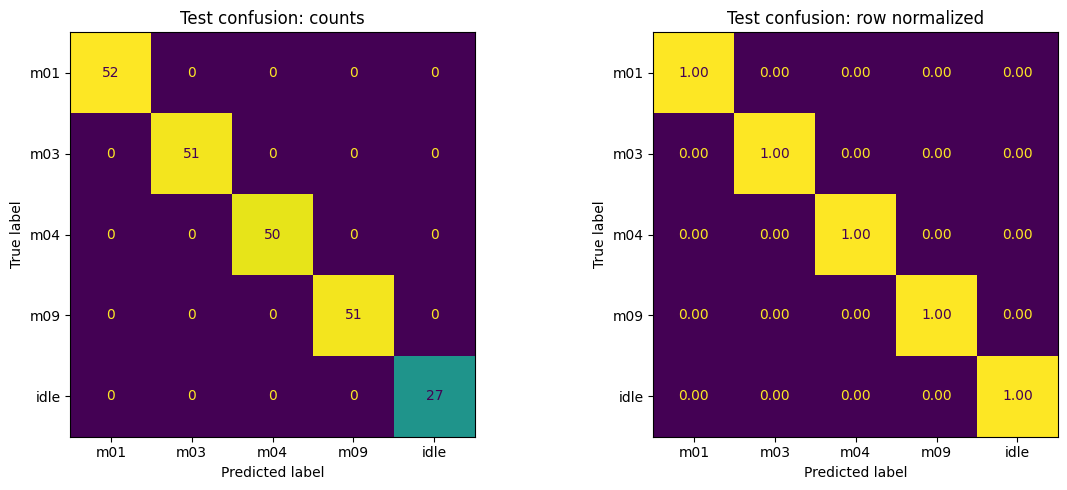

,subject,accuracy,macro_f1
0,mp_person01,1.0,1.0
1,ui_s09,1.0,1.0
2,ui_s10,1.0,1.0


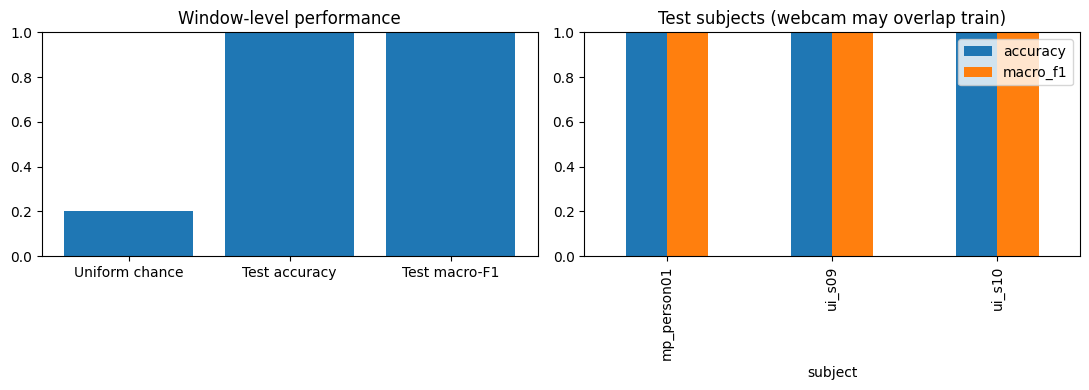

Recording accuracy (not real-time): 1.0


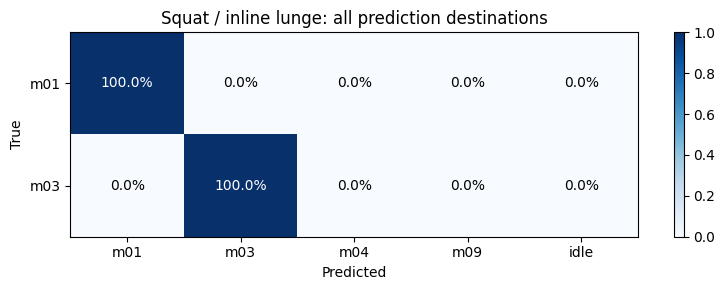

{'squat_lunge_subset_accuracy': 1.0, 'squat_to_lunge_rate': 0.0, 'lunge_to_squat_rate': 0.0}


,source,n,labels_present,accuracy
0,mediapipe,27,[4],1.0
1,vicon,204,"[0, 1, 2, 3]",1.0


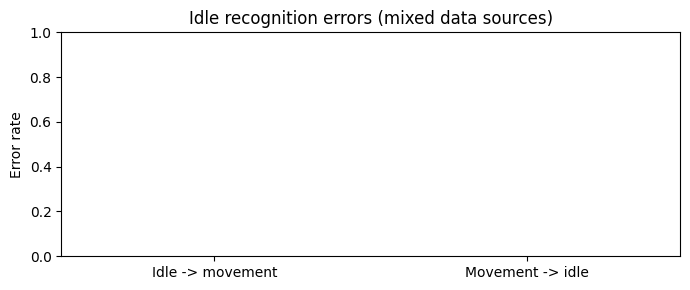

Idle -> movement: 0.0 Movement -> idle: 0.0


In [10]:
result=run_epoch(loaders['test'])
truth=result['truth']; prob=result['prob']; pred=prob.argmax(1)
metrics=dict(window_accuracy=float(accuracy_score(truth,pred)),
             window_macro_f1=float(f1_score(truth,pred,average='macro')),
             window_balanced_accuracy=float(balanced_accuracy_score(truth,pred)),
             best_validation_macro_f1=float(best),best_epoch=best_epoch)
print(json.dumps(metrics,indent=2))
report=classification_report(truth,pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,
                             output_dict=True,zero_division=0)
display(pd.DataFrame(report).T)
pd.DataFrame(report).T.to_csv(OUT/'classification_report.csv')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,norm in zip(axes,[None,'true']):
    ConfusionMatrixDisplay.from_predictions(truth,pred,labels=range(NUM_CLASSES),display_labels=CODES,
        normalize=norm,values_format='.2f' if norm else 'd',ax=ax,colorbar=False)
    ax.set_title('Test confusion: '+('row normalized' if norm else 'counts'))
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png',dpi=160); plt.show()
details=META['test'].copy(); details['true']=truth; details['pred']=pred
details['confidence']=prob.max(1)
for i,c in enumerate(CODES): details[c+'_prob']=prob[:,i]
details.to_csv(OUT/'test_predictions.csv',index=False)
subject_scores=[]
for subject,group in details.groupby('subject'):
    subject_scores.append(dict(subject=subject,accuracy=accuracy_score(group.true,group.pred),
        macro_f1=f1_score(group.true,group.pred,labels=sorted(group.true.unique()),average='macro',zero_division=0)))
subject_scores=pd.DataFrame(subject_scores)
display(subject_scores); subject_scores.to_csv(OUT/'subject_scores.csv',index=False)
record_scores=details.groupby('file')[[c+'_prob' for c in CODES]].mean()
record_truth=details.groupby('file').true.first().loc[record_scores.index]
metrics['recording_accuracy']=float(accuracy_score(record_truth,record_scores.values.argmax(1)))
metrics['test_subjects']=sorted(details.subject.unique().tolist())
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(['Uniform chance','Test accuracy','Test macro-F1'],[1/NUM_CLASSES,metrics['window_accuracy'],metrics['window_macro_f1']])
axes[0].set_ylim(0,1); axes[0].set_title('Window-level performance')
subject_scores.set_index('subject').plot.bar(ax=axes[1],ylim=(0,1),title='Test subjects (webcam may overlap train)')
plt.tight_layout(); plt.savefig(OUT/'performance_summary.png',dpi=160); plt.show()
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Recording accuracy (not real-time):',metrics['recording_accuracy'])

# Keep all six output classes: errors to M04/M06/M07 must not be hidden.
cm=confusion_matrix(truth,pred,labels=range(NUM_CLASSES))
pair=np.isin(truth,[0,1])
metrics['squat_lunge_subset_accuracy']=float(accuracy_score(truth[pair],pred[pair]))
metrics['squat_to_lunge_rate']=float(cm[0,1]/cm[0].sum())
metrics['lunge_to_squat_rate']=float(cm[1,0]/cm[1].sum())
metrics['feature_schema']=FEATURE_SCHEMA
fig,ax=plt.subplots(figsize=(8,3))
pair_cm=cm[:2]/cm[:2].sum(axis=1,keepdims=True)
im=ax.imshow(pair_cm,vmin=0,vmax=1,cmap='Blues',aspect='auto')
ax.set(xticks=range(NUM_CLASSES),xticklabels=CODES,yticks=range(2),yticklabels=CODES[:2],
       xlabel='Predicted',ylabel='True',title='Squat / inline lunge: all prediction destinations')
for row in range(2):
    for col in range(NUM_CLASSES):
        ax.text(col,row,f'{pair_cm[row,col]:.1%}',ha='center',va='center',
                color='white' if pair_cm[row,col]>.5 else 'black')
plt.colorbar(im,ax=ax); plt.tight_layout()
plt.savefig(OUT/'squat_lunge_confusion.png',dpi=160); plt.show()
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print({k:v for k,v in metrics.items() if 'squat' in k or 'lunge' in k})

# Idle error rates and source-specific support; aggregate scores can hide sensor shortcuts.
idle_id=CODES.index('idle')
metrics['idle_to_movement_rate']=float(np.mean(pred[truth==idle_id]!=idle_id))
metrics['movement_to_idle_rate']=float(np.mean(pred[truth!=idle_id]==idle_id))
metrics['webcam_shared_subjects']=shared_subjects
source_rows=[]
for source, group in details.groupby('source'):
    source_rows.append(dict(source=source,n=len(group),labels_present=sorted(group.true.unique().tolist()),
        accuracy=float(accuracy_score(group.true,group.pred))))
display(pd.DataFrame(source_rows))
pd.DataFrame(source_rows).to_csv(OUT/'source_scores.csv',index=False)
fig,ax=plt.subplots(figsize=(7,3))
ax.bar(['Idle -> movement','Movement -> idle'],
       [metrics['idle_to_movement_rate'],metrics['movement_to_idle_rate']])
ax.set(ylim=(0,1),ylabel='Error rate',title='Idle recognition errors (mixed data sources)')
plt.tight_layout(); plt.savefig(OUT/'idle_errors.png',dpi=160); plt.show()
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Idle -> movement:',metrics['idle_to_movement_rate'],'Movement -> idle:',metrics['movement_to_idle_rate'])


### 4-1. 베이스라인 모델: LSTM 학습·평가
TCN과 비교할 **직접 학습한 베이스라인**으로 단순한 LSTM을 처음부터 학습합니다. 비교를 공정하게 하기 위해 TCN과 같은 조건을 사용합니다.

- 입력 `[B, 90, 54]`, 같은 train/val/test 창, 모델 내부의 같은 train 평균·표준편차 표준화
- 같은 optimizer(AdamW, lr 0.001, weight decay 0.0001), batch 64, 클래스 가중 Cross Entropy, gradient clipping 1.0, 좌우 반전 증강
- 최대 100 epoch, Validation Macro-F1 기준 checkpoint 선택, 15 epoch early stopping, seed 42

구조: 2층 단방향 LSTM(hidden 64, 층 사이 dropout 0.2) → 마지막 시점의 hidden state → Linear(64 → 5).
TCN의 `model`, `optimizer`와 4절의 test 결과 변수(`truth`, `pred`, `details`)는 바꾸지 않고, LSTM 결과는 `lstm_` 접두사 파일로 따로 저장합니다.

LSTM parameters: 64325 | TCN parameters: 101765
[LSTM] epoch 001 | train loss 1.5169 | val F1 0.8387 | best 0.8387
[LSTM] epoch 002 | train loss 1.2234 | val F1 0.9806 | best 0.9806
[LSTM] epoch 003 | train loss 0.7243 | val F1 0.9956 | best 0.9956
[LSTM] epoch 004 | train loss 0.3372 | val F1 1.0000 | best 1.0000
[LSTM] epoch 005 | train loss 0.1602 | val F1 1.0000 | best 1.0000
[LSTM] epoch 006 | train loss 0.0884 | val F1 1.0000 | best 1.0000
[LSTM] epoch 007 | train loss 0.0637 | val F1 1.0000 | best 1.0000
[LSTM] epoch 008 | train loss 0.0456 | val F1 1.0000 | best 1.0000
[LSTM] epoch 009 | train loss 0.0278 | val F1 1.0000 | best 1.0000
[LSTM] epoch 010 | train loss 0.0192 | val F1 1.0000 | best 1.0000
[LSTM] epoch 011 | train loss 0.0154 | val F1 1.0000 | best 1.0000
[LSTM] epoch 012 | train loss 0.0125 | val F1 1.0000 | best 1.0000
[LSTM] epoch 013 | train loss 0.0108 | val F1 1.0000 | best 1.0000
[LSTM] epoch 014 | train loss 0.0101 | val F1 1.0000 | best 1.0000
[LSTM] epoch 0

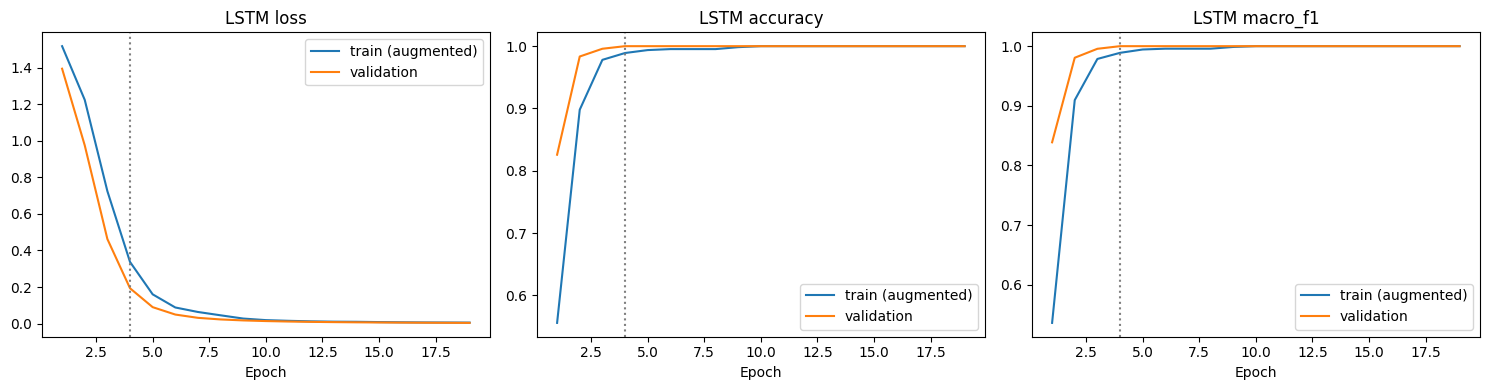

,precision,recall,f1-score,support
M01 Deep Squat,0.894737,0.980769,0.935780,52.000000
M03 Inline Lunge,1.000000,1.000000,1.000000,51.000000
M04 Side Lunge,0.925926,1.000000,0.961538,50.000000
M09 Standing Shoulder Internal-External Rotation,0.976190,0.803922,0.881720,51.000000
IDLE Standing Rest,1.000000,1.000000,1.000000,27.000000
accuracy,0.952381,0.952381,0.952381,0.952381
macro avg,0.959371,0.956938,0.955808,231.000000
weighted avg,0.955014,0.952381,0.951105,231.000000


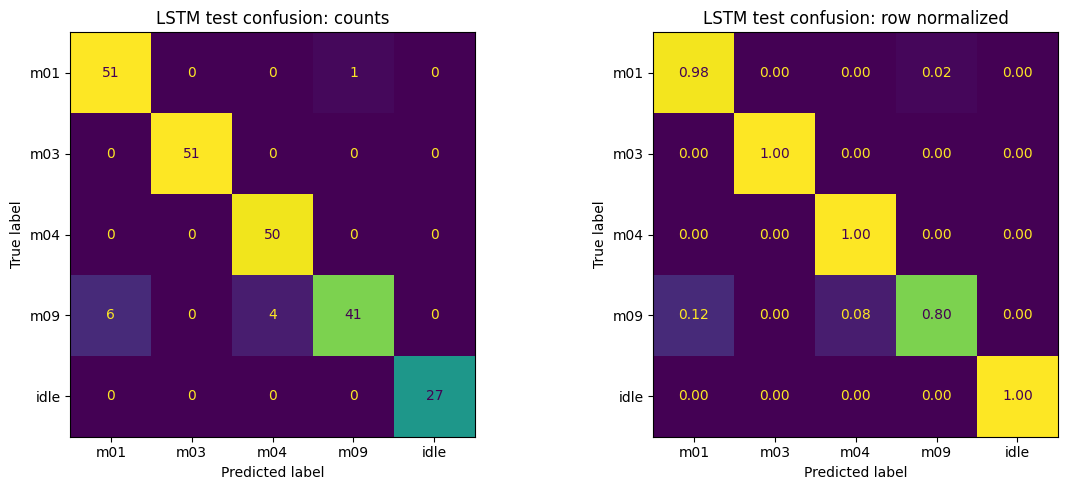

{
  "window_accuracy": 0.9523809523809523,
  "window_macro_f1": 0.95580774163195,
  "window_balanced_accuracy": 0.9569381598793363,
  "recording_accuracy": 1.0,
  "squat_to_lunge_rate": 0.0,
  "lunge_to_squat_rate": 0.0,
  "best_validation_macro_f1": 1.0,
  "best_epoch": 4,
  "epochs_run": 19,
  "parameters": 64325,
  "hidden": 64,
  "layers": 2
}


898

In [11]:
LSTM_SOURCE = """import torch
from torch import nn

class PoseLSTM(nn.Module):
    def __init__(self,cfg,mean,std,hidden=64,layers=2):
        super().__init__()
        self.register_buffer('mean',torch.as_tensor(mean,dtype=torch.float32))
        self.register_buffer('std',torch.as_tensor(std,dtype=torch.float32))
        self.lstm=nn.LSTM(cfg['input_features'],hidden,num_layers=layers,batch_first=True,
                          dropout=cfg['dropout'] if layers>1 else 0.)
        self.drop=nn.Dropout(cfg['dropout'])
        self.head=nn.Linear(hidden,cfg['num_classes'])
    def forward(self,x):
        out,_=self.lstm((x-self.mean)/self.std)
        return self.head(self.drop(out[:,-1]))
"""
exec(LSTM_SOURCE)
(OUT/'lstm_model.py').write_text(LSTM_SOURCE,encoding='utf-8')
LSTM_CFG=dict(hidden=64,layers=2)

# Same seed and data order as the TCN run; TCN objects are left untouched.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
lstm_model=PoseLSTM(CFG,mean,std,**LSTM_CFG).to(DEVICE)
lstm_params=sum(p.numel() for p in lstm_model.parameters())
tcn_params=sum(p.numel() for p in model.parameters())
print('LSTM parameters:',lstm_params,'| TCN parameters:',tcn_params)
lstm_optimizer=torch.optim.AdamW(lstm_model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])

def run_lstm_epoch(loader, training=False):
    lstm_model.train(training)
    losses=[]; truths=[]; probs=[]
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        if training: x=augment(x)
        with torch.set_grad_enabled(training):
            logits=lstm_model(x); loss=criterion(logits,y)
            if training:
                lstm_optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(lstm_model.parameters(),1.0)
                lstm_optimizer.step()
        losses.append((loss.item(),len(y)))
        truths.extend(y.cpu().numpy()); probs.append(logits.detach().softmax(-1).cpu().numpy())
    truth_=np.asarray(truths); prob_=np.concatenate(probs); pred_=prob_.argmax(1)
    return dict(loss=sum(l*n for l,n in losses)/sum(n for _,n in losses),
                accuracy=accuracy_score(truth_,pred_),
                macro_f1=f1_score(truth_,pred_,labels=range(NUM_CLASSES),average='macro',zero_division=0),
                truth=truth_,prob=prob_)

lstm_history=[]; lstm_best=-1.; stale=0; lstm_best_epoch=0
for epoch in range(1,CFG['epochs']+1):
    tr=run_lstm_epoch(loaders['train'],True); va=run_lstm_epoch(loaders['val'])
    lstm_history.append(dict(epoch=epoch,**{'train_'+k:tr[k] for k in ['loss','accuracy','macro_f1']},
                             **{'val_'+k:va[k] for k in ['loss','accuracy','macro_f1']}))
    if va['macro_f1']>lstm_best+1e-5:
        lstm_best=va['macro_f1']; stale=0; lstm_best_epoch=epoch
        torch.save(lstm_model.state_dict(),OUT/'lstm_best_state_dict.pt')
    else: stale+=1
    print(f"[LSTM] epoch {epoch:03d} | train loss {tr['loss']:.4f} | val F1 {va['macro_f1']:.4f} | best {lstm_best:.4f}")
    if stale>=CFG['patience']: break
lstm_model.load_state_dict(torch.load(OUT/'lstm_best_state_dict.pt',map_location=DEVICE,weights_only=True))
lstm_history=pd.DataFrame(lstm_history)
lstm_history.to_csv(OUT/'lstm_history.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['loss','accuracy','macro_f1']):
    ax.plot(lstm_history.epoch,lstm_history['train_'+metric],label='train (augmented)')
    ax.plot(lstm_history.epoch,lstm_history['val_'+metric],label='validation')
    ax.axvline(lstm_best_epoch,color='gray',linestyle=':'); ax.set_title('LSTM '+metric); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'lstm_learning_curves.png',dpi=160); plt.show()

# Test evaluation with the same metrics and files as the TCN section.
lstm_result=run_lstm_epoch(loaders['test'])
assert np.array_equal(lstm_result['truth'],truth), 'Test order must match the TCN evaluation'
lstm_prob=lstm_result['prob']; lstm_pred=lstm_prob.argmax(1)
lstm_report=classification_report(truth,lstm_pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,
                                  output_dict=True,zero_division=0)
display(pd.DataFrame(lstm_report).T)
pd.DataFrame(lstm_report).T.to_csv(OUT/'lstm_classification_report.csv')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,norm in zip(axes,[None,'true']):
    ConfusionMatrixDisplay.from_predictions(truth,lstm_pred,labels=range(NUM_CLASSES),display_labels=CODES,
        normalize=norm,values_format='.2f' if norm else 'd',ax=ax,colorbar=False)
    ax.set_title('LSTM test confusion: '+('row normalized' if norm else 'counts'))
plt.tight_layout(); plt.savefig(OUT/'lstm_confusion_matrix.png',dpi=160); plt.show()
lstm_details=META['test'].copy(); lstm_details['true']=truth; lstm_details['pred']=lstm_pred
lstm_details['confidence']=lstm_prob.max(1)
for i,c in enumerate(CODES): lstm_details[c+'_prob']=lstm_prob[:,i]
lstm_details.to_csv(OUT/'lstm_test_predictions.csv',index=False)
lstm_record_scores=lstm_details.groupby('file')[[c+'_prob' for c in CODES]].mean()
lstm_record_truth=lstm_details.groupby('file').true.first().loc[lstm_record_scores.index]
lstm_cm=confusion_matrix(truth,lstm_pred,labels=range(NUM_CLASSES))
lstm_metrics=dict(window_accuracy=float(accuracy_score(truth,lstm_pred)),
                  window_macro_f1=float(f1_score(truth,lstm_pred,average='macro')),
                  window_balanced_accuracy=float(balanced_accuracy_score(truth,lstm_pred)),
                  recording_accuracy=float(accuracy_score(lstm_record_truth,lstm_record_scores.values.argmax(1))),
                  squat_to_lunge_rate=float(lstm_cm[0,1]/lstm_cm[0].sum()),
                  lunge_to_squat_rate=float(lstm_cm[1,0]/lstm_cm[1].sum()),
                  best_validation_macro_f1=float(lstm_best),best_epoch=lstm_best_epoch,
                  epochs_run=int(len(lstm_history)),parameters=int(lstm_params),**LSTM_CFG)
print(json.dumps(lstm_metrics,indent=2))
metrics['lstm_baseline']=lstm_metrics
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')

### 4-2. Dummy baseline과 TCN 비교 (UI-PRMD test)
입력 특징을 전혀 보지 않고 **train 라벨 분포만** 사용하는 `sklearn.dummy.DummyClassifier`를 기준선으로 두고, 같은 test 창에서 TCN과 비교합니다.

| 기준선 | 예측 방식 |
|---|---|
| `most_frequent` | train에서 가장 많은 클래스 하나만 항상 예측 |
| `stratified` | train 클래스 비율대로 무작위 예측 |
| `uniform` | 5개 클래스를 같은 확률로 무작위 예측 |

무작위 기준선은 seed 10개의 평균±표준편차로 기록합니다. 평가 범위는 **UI-PRMD(Vicon) test 4개 운동**과 웹캠 idle을 포함한 **전체 test 5클래스** 두 가지입니다. 결과는 `baseline_comparison.csv`/`baseline_comparison.md`로 저장되어 출력 ZIP에 포함되며, `metrics.json`에도 요약이 추가됩니다.
기준선보다 높다는 것은 모델이 라벨 분포 이상의 정보를 사용한다는 뜻일 뿐, 실제 웹캠 운동 인식 성능을 보장하지 않습니다.

,scope,model,test_windows,runs,accuracy,accuracy_std,macro_f1,macro_f1_std,balanced_accuracy,balanced_accuracy_std,macro_f1_gap_vs_tcn
0,UI-PRMD Vicon test (4 movements),TCN (positions + angles),204,1,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000
1,UI-PRMD Vicon test (4 movements),Dummy (most frequent),204,1,0.2451,0.0000,0.0984,0.0000,0.2500,0.0000,0.9016
2,UI-PRMD Vicon test (4 movements),Dummy (stratified),204,10,0.2083,0.0198,0.2197,0.0201,0.2085,0.0199,0.7803
3,UI-PRMD Vicon test (4 movements),Dummy (uniform),204,10,0.2069,0.0267,0.2303,0.0290,0.2070,0.0266,0.7697
4,Full test (Vicon + webcam idle),TCN (positions + angles),231,1,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000
5,Full test (Vicon + webcam idle),Dummy (most frequent),231,1,0.2165,0.0000,0.0712,0.0000,0.2000,0.0000,0.9288
6,Full test (Vicon + webcam idle),Dummy (stratified),231,10,0.1965,0.0208,0.1861,0.0221,0.1883,0.0225,0.8139
7,Full test (Vicon + webcam idle),Dummy (uniform),231,10,0.1996,0.0253,0.1944,0.0252,0.1945,0.0259,0.8056


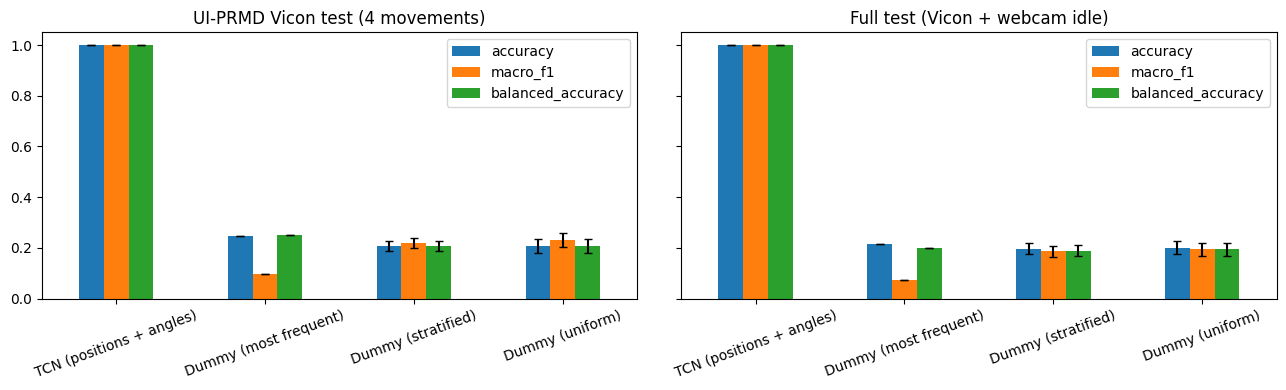

Saved: /content/ui_prmd_tcn_output/baseline_comparison.csv /content/ui_prmd_tcn_output/baseline_comparison.md /content/ui_prmd_tcn_output/baseline_comparison.png


In [12]:
import warnings
from sklearn.dummy import DummyClassifier

BASELINE_SEEDS = list(range(SEED, SEED+10))
STRATEGIES = {'most_frequent': 'Dummy (most frequent)',
              'stratified': 'Dummy (stratified)',
              'uniform': 'Dummy (uniform)'}
scopes = {'UI-PRMD Vicon test (4 movements)': (details.source=='vicon').to_numpy(),
          'Full test (Vicon + webcam idle)': np.ones(len(details),dtype=bool)}

def score(y_true, y_pred):
    # Dummy may predict idle on the Vicon-only scope; that is a scored error, not a bug.
    warnings.filterwarnings('ignore',message='y_pred contains classes not in y_true')
    labels = sorted(np.unique(y_true))
    return dict(accuracy=accuracy_score(y_true,y_pred),
                macro_f1=f1_score(y_true,y_pred,labels=labels,average='macro',zero_division=0),
                balanced_accuracy=balanced_accuracy_score(y_true,y_pred))

# Dummy models see only train labels; placeholder features make that explicit.
baseline_rows=[]
for scope,mask in scopes.items():
    y_true=truth[mask]
    rows={'TCN (positions + angles)':[score(y_true,pred[mask])]}
    for strategy,name in STRATEGIES.items():
        seeds=[SEED] if strategy=='most_frequent' else BASELINE_SEEDS
        runs=[]
        for s in seeds:
            dummy=DummyClassifier(strategy=strategy,random_state=s)
            dummy.fit(np.zeros((len(Y['train']),1)),Y['train'])
            runs.append(score(y_true,dummy.predict(np.zeros((mask.sum(),1)))))
        rows[name]=runs
    for name,runs in rows.items():
        frame=pd.DataFrame(runs)
        row=dict(scope=scope,model=name,test_windows=int(mask.sum()),runs=len(runs))
        for metric in ['accuracy','macro_f1','balanced_accuracy']:
            row[metric]=float(frame[metric].mean())
            row[metric+'_std']=float(frame[metric].std(ddof=0))
        baseline_rows.append(row)
baseline_table=pd.DataFrame(baseline_rows)
for scope in scopes:
    part=baseline_table[baseline_table.scope==scope]
    tcn_f1=part[part.model=='TCN (positions + angles)'].macro_f1.iloc[0]
    baseline_table.loc[part.index,'macro_f1_gap_vs_tcn']=tcn_f1-part.macro_f1
display(baseline_table.round(4))
baseline_table.to_csv(OUT/'baseline_comparison.csv',index=False)

def cell(row,metric):
    text=f"{row[metric]:.4f}"
    return text+(f" ± {row[metric+'_std']:.4f}" if row.runs>1 else '')
md=['# Dummy baseline vs TCN (test set)','',
    f"Dummy models are fit on train labels only. Random strategies: mean ± std over seeds {BASELINE_SEEDS[0]}-{BASELINE_SEEDS[-1]}.",'']
for scope in scopes:
    md+=[f'## {scope}','','| Model | Windows | Accuracy | Macro-F1 | Balanced Acc. | TCN F1 gap |','|---|---:|---:|---:|---:|---:|']
    for _,row in baseline_table[baseline_table.scope==scope].iterrows():
        md.append(f"| {row.model} | {row.test_windows} | {cell(row,'accuracy')} | {cell(row,'macro_f1')} | "
                  f"{cell(row,'balanced_accuracy')} | {row.macro_f1_gap_vs_tcn:+.4f} |")
    md.append('')
(OUT/'baseline_comparison.md').write_text('\n'.join(md),encoding='utf-8')

fig,axes=plt.subplots(1,len(scopes),figsize=(13,4),sharey=True)
for ax,scope in zip(axes,scopes):
    part=baseline_table[baseline_table.scope==scope].set_index('model')
    part[['accuracy','macro_f1','balanced_accuracy']].plot.bar(
        ax=ax,yerr=part[['accuracy_std','macro_f1_std','balanced_accuracy_std']].rename(columns=lambda c:c[:-4]),capsize=3)
    ax.set(ylim=(0,1.05),title=scope,xlabel=''); ax.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.savefig(OUT/'baseline_comparison.png',dpi=160); plt.show()

metrics['baseline_comparison']={scope:{row.model:dict(accuracy=row.accuracy,macro_f1=row.macro_f1,
    balanced_accuracy=row.balanced_accuracy) for _,row in baseline_table[baseline_table.scope==scope].iterrows()}
    for scope in scopes}
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Saved:',OUT/'baseline_comparison.csv',OUT/'baseline_comparison.md',OUT/'baseline_comparison.png')

### 4-3. 최종 모델 비교와 선택: TCN vs LSTM
같은 test 창에서 직접 학습한 두 모델(제안 TCN, 베이스라인 LSTM)과 4-2절의 dummy 기준선을 한 표로 정리합니다.
비교 지표는 Accuracy, Macro-F1, Balanced Accuracy, 녹화 단위 Accuracy, M01↔M03 혼동률이며 파라미터 수와 선택 epoch도 함께 기록합니다.

**최종 모델 선택 규칙:** test Macro-F1이 높은 모델 → 같으면 Balanced Accuracy → 같으면 서비스 연동이 완료된 TCN.
선택한 TCN만 TorchScript로 내보내 서버에서 사용합니다. 결과는 `model_comparison.csv`, `model_comparison.md`, `model_comparison.png`, `misclassified_examples.csv`로 저장하고 `metrics.json`에 `final_model`을 기록합니다.

,model,type,accuracy,macro_f1,balanced_accuracy,squat_to_lunge_rate,lunge_to_squat_rate,recording_accuracy,best_validation_macro_f1,best_epoch,epochs_run,parameters,selected
0,TCN (proposed),trained from scratch,1.0000,1.0000,1.0000,0.0,0.0,1.0,1.0,1.0,16.0,101765.0,True
1,LSTM (baseline),trained from scratch,0.9524,0.9558,0.9569,0.0,0.0,1.0,1.0,4.0,19.0,64325.0,False
2,Dummy (most frequent),label prior only,0.2165,0.0712,0.2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,Dummy (stratified),label prior only,0.1965,0.1861,0.1883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,Dummy (uniform),label prior only,0.1996,0.1944,0.1945,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


Final model: TCN (proposed) - test Macro-F1 1.0000로 가장 높음
Misclassified windows - TCN: 0 | LSTM: 11


,file,subject,source,start_frame,true,tcn_pred,lstm_pred,tcn_confidence,lstm_confidence
51,m01_s10_positions.txt,ui_s10,vicon,690,m01,m01,m09,0.965168,0.489282
187,m09_s10_positions.txt,ui_s10,vicon,0,m09,m09,m01,0.944873,0.540830
188,m09_s10_positions.txt,ui_s10,vicon,30,m09,m09,m01,0.941333,0.574146
189,m09_s10_positions.txt,ui_s10,vicon,60,m09,m09,m01,0.941728,0.440387
190,m09_s10_positions.txt,ui_s10,vicon,90,m09,m09,m01,0.932383,0.366704
191,m09_s10_positions.txt,ui_s10,vicon,120,m09,m09,m04,0.940817,0.376634
195,m09_s10_positions.txt,ui_s10,vicon,240,m09,m09,m04,0.936595,0.394128
197,m09_s10_positions.txt,ui_s10,vicon,300,m09,m09,m01,0.938345,0.381414
199,m09_s10_positions.txt,ui_s10,vicon,360,m09,m09,m01,0.942236,0.351777
200,m09_s10_positions.txt,ui_s10,vicon,390,m09,m09,m04,0.945824,0.373205


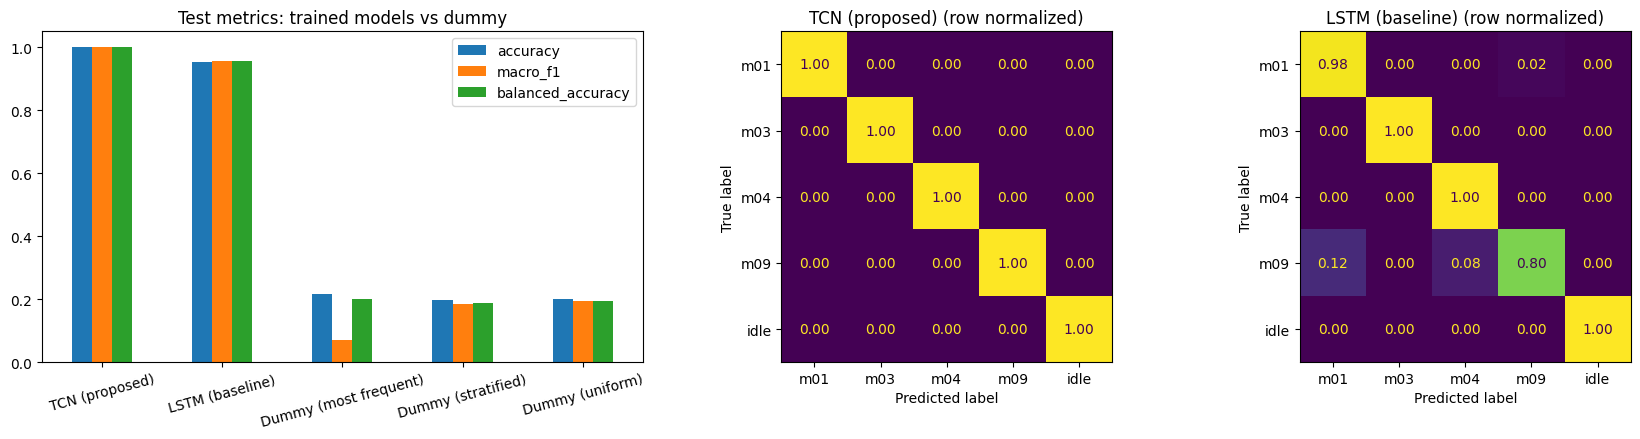

Saved: /content/ui_prmd_tcn_output/model_comparison.csv /content/ui_prmd_tcn_output/model_comparison.md /content/ui_prmd_tcn_output/model_comparison.png /content/ui_prmd_tcn_output/misclassified_examples.csv


In [13]:
def window_scores(y_true,y_pred):
    cm_=confusion_matrix(y_true,y_pred,labels=range(NUM_CLASSES))
    return dict(accuracy=accuracy_score(y_true,y_pred),
                macro_f1=f1_score(y_true,y_pred,labels=range(NUM_CLASSES),average='macro',zero_division=0),
                balanced_accuracy=balanced_accuracy_score(y_true,y_pred),
                squat_to_lunge_rate=cm_[0,1]/max(cm_[0].sum(),1),
                lunge_to_squat_rate=cm_[1,0]/max(cm_[1].sum(),1))

trained={'TCN (proposed)':dict(pred=pred,params=tcn_params,best_epoch=best_epoch,epochs_run=len(history),
                               val_f1=best,recording_accuracy=metrics['recording_accuracy']),
         'LSTM (baseline)':dict(pred=lstm_pred,params=lstm_params,best_epoch=lstm_best_epoch,
                                epochs_run=len(lstm_history),val_f1=lstm_best,
                                recording_accuracy=lstm_metrics['recording_accuracy'])}
comparison_rows=[]
for name,info in trained.items():
    comparison_rows.append(dict(model=name,type='trained from scratch',**window_scores(truth,info['pred']),
        recording_accuracy=info['recording_accuracy'],best_validation_macro_f1=info['val_f1'],
        best_epoch=info['best_epoch'],epochs_run=info['epochs_run'],parameters=info['params']))
full_scope='Full test (Vicon + webcam idle)'
for _,row in baseline_table[(baseline_table.scope==full_scope)&baseline_table.model.str.startswith('Dummy')].iterrows():
    comparison_rows.append(dict(model=row.model,type='label prior only',accuracy=row.accuracy,
        macro_f1=row.macro_f1,balanced_accuracy=row.balanced_accuracy))
model_comparison=pd.DataFrame(comparison_rows)

ranked=model_comparison[model_comparison.type=='trained from scratch'].copy()
ranked['tcn_first']=ranked.model.str.startswith('TCN')
ranked=ranked.sort_values(['macro_f1','balanced_accuracy','tcn_first'],ascending=False)
FINAL_MODEL=ranked.model.iloc[0]
model_comparison['selected']=model_comparison.model==FINAL_MODEL
display(model_comparison.round(4))
model_comparison.to_csv(OUT/'model_comparison.csv',index=False)

tcn_row=model_comparison[model_comparison.model=='TCN (proposed)'].iloc[0]
lstm_row=model_comparison[model_comparison.model=='LSTM (baseline)'].iloc[0]
tie=np.isclose(tcn_row.macro_f1,lstm_row.macro_f1) and np.isclose(tcn_row.balanced_accuracy,lstm_row.balanced_accuracy)
reason=('test Macro-F1과 Balanced Accuracy가 같아, 서비스 연동이 완료된 TCN을 선택' if tie else
        f"test Macro-F1 {ranked.macro_f1.iloc[0]:.4f}로 가장 높음")
print('Final model:',FINAL_MODEL,'-',reason)
if FINAL_MODEL!='TCN (proposed)':
    print('주의: LSTM이 TCN보다 높습니다. 서버는 TCN을 로드하므로 README의 최종 모델 근거를 다시 검토하세요.')

def fmt(v,digits=4):
    return '—' if pd.isna(v) else (f'{int(v):,}' if digits==0 else f'{v:.{digits}f}')
md=['# Model comparison (test set, 231 windows)','',
    '| Model | Type | Accuracy | Macro-F1 | Balanced Acc. | Recording Acc. | M01→M03 | M03→M01 | Params | Best epoch |',
    '|---|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for _,r in model_comparison.iterrows():
    name=f'**{r.model}** ✔' if r.selected else r.model
    md.append(f"| {name} | {r.type} | {fmt(r.accuracy)} | {fmt(r.macro_f1)} | {fmt(r.balanced_accuracy)} | "
              f"{fmt(r.get('recording_accuracy'))} | {fmt(r.get('squat_to_lunge_rate'))} | {fmt(r.get('lunge_to_squat_rate'))} | "
              f"{fmt(r.get('parameters'),0)} | {fmt(r.get('best_epoch'),0)} |")
md+=['',f'Final model: **{FINAL_MODEL}** — {reason}.',
     'Dummy rows are mean values over seeds; see baseline_comparison.md for standard deviations.']
(OUT/'model_comparison.md').write_text('\n'.join(md),encoding='utf-8')

# Error cases of either trained model (empty table when both are perfect).
errors=details[['file','subject','source','start_frame','true']].copy()
errors['tcn_pred']=pred; errors['lstm_pred']=lstm_pred
errors['tcn_confidence']=prob.max(1); errors['lstm_confidence']=lstm_prob.max(1)
errors=errors[(errors.tcn_pred!=errors.true)|(errors.lstm_pred!=errors.true)]
for col in ['true','tcn_pred','lstm_pred']: errors[col]=errors[col].map(dict(enumerate(CODES)))
errors.to_csv(OUT/'misclassified_examples.csv',index=False)
print('Misclassified windows - TCN:',int((pred!=truth).sum()),'| LSTM:',int((lstm_pred!=truth).sum()))
display(errors.head(20))

fig,axes=plt.subplots(1,3,figsize=(17,4.5),gridspec_kw=dict(width_ratios=[1.4,1,1]))
plot_df=model_comparison.set_index('model')[['accuracy','macro_f1','balanced_accuracy']]
plot_df.plot.bar(ax=axes[0],ylim=(0,1.05),rot=15,title='Test metrics: trained models vs dummy')
axes[0].set_xlabel('')
for ax,(name,y_pred) in zip(axes[1:],[('TCN (proposed)',pred),('LSTM (baseline)',lstm_pred)]):
    ConfusionMatrixDisplay.from_predictions(truth,y_pred,labels=range(NUM_CLASSES),display_labels=CODES,
        normalize='true',values_format='.2f',ax=ax,colorbar=False)
    ax.set_title(name+' (row normalized)')
plt.tight_layout(); plt.savefig(OUT/'model_comparison.png',dpi=160); plt.show()

metrics['final_model']=dict(name=FINAL_MODEL,reason=reason,
    rule='test macro-F1 -> balanced accuracy -> TCN (deployed) on ties')
metrics['model_comparison']={r.model:{k:(None if pd.isna(r[k]) else float(r[k]))
    for k in ['accuracy','macro_f1','balanced_accuracy']} for _,r in model_comparison.iterrows()}
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8')
print('Saved:',*[OUT/f for f in ['model_comparison.csv','model_comparison.md','model_comparison.png','misclassified_examples.csv']])

## 5. 통합 모델 저장·재로드 검증·다운로드
새 ZIP: **ui_prmd_tcn_output.zip**, 내부 폴더도 ui_prmd_tcn_output입니다. 입력은 [B,90,54] float32: 위치 36개(몸통 길이 기준) 뒤에 각도 18개(radians/π)입니다. 채널별 표준화는 모델 내부에서 수행됩니다.
공통 소스 preprocess.py와 metadata에 feature_schema=positions_angles_v1, 특징 이름/단위 54개, 소스 SHA-256, 입력 차원을 저장합니다. 모델/metadata/preprocess를 폴더 단위로 함께 설치하세요.
학습 후 압축을 프로젝트 루트에 풀고 서버를 재시작합니다. 기존 같은 이름의 결과가 있다면 비교를 위해 먼저 별도 보관하세요. 서버 기본 경로도 ui_prmd_tcn_output이며 이전 각도 전용 폴더를 자동 선택하지 않습니다.


In [14]:
model=model.cpu().eval()
example=torch.from_numpy(X['test'][:2])
traced=torch.jit.trace(model,example)
traced.save(str(OUT/'pose_tcn.torchscript.pt'))
loaded=torch.jit.load(str(OUT/'pose_tcn.torchscript.pt')).eval()
with torch.no_grad():
    for n in [1,2]:
        torch.testing.assert_close(loaded(example[:n]),model(example[:n]),atol=1e-5,rtol=1e-5)
metadata=dict(config=CFG,classes=CLASSES,codes=CODES,joints=JOINTS,
              vicon_marker_groups_zero_based=VICON_GROUPS,mediapipe_indices=MP_IDS,
              splits=SPLITS,input_shape=['batch',CFG['window'],CFG['input_features']],input_dtype='float32',
              input='36 body-normalized XYZ + 18 angles; per-channel standardization inside model',
              feature_schema=FEATURE_SCHEMA,feature_names=FEATURE_NAMES,feature_units=FEATURE_UNITS,
              preprocess_sha256=hashlib.sha256(PREPROCESS_SOURCE.encode('utf-8')).hexdigest(),
              vicon_up=[0,0,1],mediapipe_up=[0,-1,0],
              source='Vicon movement XYZ + labeled MediaPipe world XYZ recordings',
              webcam_recordings=webcam_audit,webcam_shared_subjects=shared_subjects,
              evaluation_protocol='Vicon subject split; webcam recording split unless strict mode enabled',
              versions=dict(python=platform.python_version(),torch=torch.__version__,
                  numpy=np.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__))
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
print('Reload equivalence passed. Artifacts:',OUT)
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name)
print(archive)
COPY_TO_DRIVE = True
if COPY_TO_DRIVE and Path('/content/drive/MyDrive').is_dir():
    shutil.copy2(archive,'/content/drive/MyDrive/ui_prmd_tcn_output.zip')
    print('Copied to Google Drive')


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Reload equivalence passed. Artifacts: /content/ui_prmd_tcn_output
/content/ui_prmd_tcn_output.zip
Copied to Google Drive


In [15]:
# Colab에서 PC로 다운로드 (선택)
DOWNLOAD = True
if DOWNLOAD:
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        print('Local Jupyter: open',archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. 서버와 동일한 XYZ JSON → 위치+각도 추론 예시
서버는 브라우저에서 받은 공통 12관절 XYZ를 내부 33-landmark 형식으로 어댑트한 후, 이 노트북에서 저장한 `mediapipe_json_window()`로 변환합니다. 이 함수는 XYZ 시간 보간 → 위치 정규화 36개 + 각도 18개 계산 순서입니다. JSON 자체는 XYZ로 유지하며 브라우저에서 각도를 계산하지 않습니다.
아래 예시는 이미 버퍼에 모인 JSON: coordinate_system='mediapipe_world', frames=[{timestamp_ms: ..., landmarks: [{x,y,z,visibility}, ...33개]}, ...] 입니다.
현재 서버의 실험 설정과 동일하게 visibility는 특징/필터에 쓰지 않고 긴 공백도 보간합니다. 긴 추적 공백은 실제 관측되지 않은 자세를 만들 수 있습니다. 단조 증가 timestamp, 유한 XYZ, 최소 약 3초 이력, 유효한 뼈 길이는 검사합니다.


In [ ]:
# 실제 JSON이 준비되었을 때만 실행됩니다.
JSON_PATH = None  # 예: '/content/mediapipe_window.json'
if JSON_PATH is not None:
    payload=json.loads(Path(JSON_PATH).read_text(encoding='utf-8'))
    features=mediapipe_json_window(payload,CFG['window'],CFG['target_fps'])
    serving_model=torch.jit.load(str(OUT/'pose_tcn.torchscript.pt')).eval()
    with torch.no_grad():
        scores=serving_model(torch.from_numpy(features[None])).softmax(-1)[0].numpy()
    print({'class':CLASSES[int(scores.argmax())],
           'softmax_score':float(scores.max()),'probabilities':scores.tolist()})


### 결과 해석과 다음 비교
각도 특징은 위치·크기·수평 회전 변화에 덜 민감하고 좌우 다리 차이를 명시적으로 나타내지만, MediaPipe의 깊이/관절 추정 오류까지 제거하지는 않습니다. 골반은 Vicon 마커 근사점이므로 센서 간 차이도 남습니다.
Vicon test의 전체 정확도 외에 M01→M03 및 M03→M01 혼동률과 실제 MediaPipe 영상 결과를 기존 위치 모델과 비교하세요. 기존 100% 결과를 새 통합 모델의 성능으로 재사용하지 않습니다. 관절 각도만으로 구분이 개선되지 않으면 별도 MediaPipe 데이터 수집/미세조정을 다음 실험으로 진행하세요.

동일한 subject split과 MediaPipe 영상에서 위치 전용 / 각도 전용 / 통합 모델을 비교하세요. 특징 중복으로 과적합이 늘 수도 있어 validation F1과 M01↔M03 혼동률을 확인합니다.
